# 채용 플랫폼 사용자 행동 분석

### 최종 지표
1. 대량성: 연속 7일 최대 지원 14건 이상
2. 집중성: 5회 이상 지원자 중 5분 이내 연속지원 비율 P90 이상
3. 다양성: 고유직무 3개 이상 OR (고유직무 2개 & 최소 직무변경간격 < 222분 OR 스위칭 4회 이상)
4. 공고 탐색성: 지원 전 마지막 상세조회→지원 시간의 유저 평균이 하위 35% 이하
5. 북마크 탐색성: 탐색부족형 OR 반복행동형

### 최종 그룹
- G0: 신호없음 (행동신호 0개)
- G1: 단일신호 (행동신호 1개)
- G2: 복합신호 (행동신호 2개 이상)
    - A. 지원행동 복합형: 지원행동 신호 2개 이상 (공고탐색·북마크 결합 유형에는 해당X)
    - B. 공고탐색 결합형: 지원행동 신호 1개 + 공고탐색성 신호 결합
    - C. 고복합 행동형: 지원행동 신호 2개 이상 + 공고탐색성 신호 결합

# 10. 행동 신호 기반 사용자 그룹 분류
5개 행동 지표의 점수를 합산하여 사용자를 신호 없음, 단일 신호, 복합 신호의 3개 그룹으로 분류한다.

- G0 (신호 없음): 행동 신호 0개
- G1 (단일 신호): 행동 신호 1개
- G2 (복합 신호): 행동 신호 2개 이상

In [127]:
# 5개 행동 지표의 최종 점수를 사용자 단위로 통합
score_cols = [
    'volume_score',
    'concentration_score',
    'diversity_score',
    'view_score',
    'bookmark_score'
]

# 지표별 최종 사용자 점수 테이블
score_tables = [
    volume_metrics[['user_uuid', 'volume_score']],
    concentration_metrics[['user_uuid', 'concentration_score']],
    diversity_score_df[['user_uuid', 'diversity_score']],
    view_score_df[['user_uuid', 'view_score']],
    bookmark_analysis_df[['user_uuid', 'bookmark_score']]
]

# 전체 지원 사용자 기준
final_user_scores = user_master[['user_uuid']].copy()

# 사용자별 5개 지표 결합
for score_table in score_tables:
    final_user_scores = final_user_scores.merge(
        score_table,
        on='user_uuid',
        how='left',
        validate='one_to_one'
    )

# 지표별 병합 결측 여부 기록
for col in score_cols:
    final_user_scores[col.replace('_score', '_null')] = (
        final_user_scores[col].isna().astype(int)
    )

# 기존 프로젝트 점수화 방식: 결측 → 0점
final_user_scores[score_cols] = (
    final_user_scores[score_cols]
    .fillna(0)
    .astype(int)
)

# 5개 행동 신호 점수 합산 (0~5점)
final_user_scores['total_score'] = (
    final_user_scores[score_cols].sum(axis=1)
)

# 검증
assert final_user_scores['user_uuid'].is_unique
assert final_user_scores[score_cols].isin([0, 1]).all().all()
assert final_user_scores['total_score'].between(0, 5).all()
assert len(final_user_scores) == len(user_master)

print(f'전체 사용자: {len(final_user_scores):,}명')

print('\n지표별 병합 결측 사용자 수')
display(
    final_user_scores[
        [col.replace('_score', '_null') for col in score_cols]
    ].sum().to_frame('결측 사용자 수')
)

print('\n최종 점수 분포')
display(
    final_user_scores['total_score']
    .value_counts()
    .sort_index()
    .rename_axis('총점')
    .reset_index(name='사용자 수')
)

display(final_user_scores.head())

전체 사용자: 10,287명

지표별 병합 결측 사용자 수


,결측 사용자 수
volume_null,0
concentration_null,0
diversity_null,70
view_null,0
bookmark_null,0



최종 점수 분포


,총점,사용자 수
0,0,6484
1,1,2941
2,2,650
3,3,163
4,4,47
5,5,2


,user_uuid,volume_score,concentration_score,diversity_score,view_score,bookmark_score,volume_null,concentration_null,diversity_null,view_null,bookmark_null,total_score
0,2ece8d7d-79b6-4522-928b-8dbae8843fab,1,0,1,0,0,0,0,0,0,0,2
1,24ffac10-a46e-4adb-af66-0074d259c809,0,0,0,0,0,0,0,0,0,0,0
2,40196d59-ab7c-4951-8a5b-eb87aac0a08b,0,0,1,0,0,0,0,0,0,0,1
3,3e20b9ee-48bc-46cd-9713-d629f0a51b59,0,0,0,0,0,0,0,0,0,0,0
4,2bc97037-032e-4137-93d4-feebaa1c2524,0,0,0,0,0,0,0,0,0,0,0


## 10-1. 사용자 그룹 생성

In [128]:
# 총점 기준 사용자 그룹 분류
final_user_scores['analysis_group'] = np.select(
    [
        final_user_scores['total_score'] == 0,
        final_user_scores['total_score'] == 1,
        final_user_scores['total_score'] >= 2
    ],
    [
        'G0_신호없음',
        'G1_단일신호',
        'G2_복합신호'
    ],
    default='확인필요'
)

# 그룹별 사용자 수 및 비율
group_order = [
    'G0_신호없음',
    'G1_단일신호',
    'G2_복합신호'
]

group_summary = (
    final_user_scores['analysis_group']
    .value_counts()
    .reindex(group_order, fill_value=0)
    .rename_axis('그룹')
    .reset_index(name='사용자 수')
)

group_summary['비율(%)'] = (
    group_summary['사용자 수']
    / len(final_user_scores) * 100
).round(1)

display(group_summary)

# 그룹별 데이터 추출
g0 = final_user_scores[
    final_user_scores['analysis_group'] == 'G0_신호없음'
].copy()

g1 = final_user_scores[
    final_user_scores['analysis_group'] == 'G1_단일신호'
].copy()

g2 = final_user_scores[
    final_user_scores['analysis_group'] == 'G2_복합신호'
].copy()

assert len(g0) + len(g1) + len(g2) == len(final_user_scores)

,그룹,사용자 수,비율(%)
0,G0_신호없음,6484,63.0
1,G1_단일신호,2941,28.6
2,G2_복합신호,862,8.4


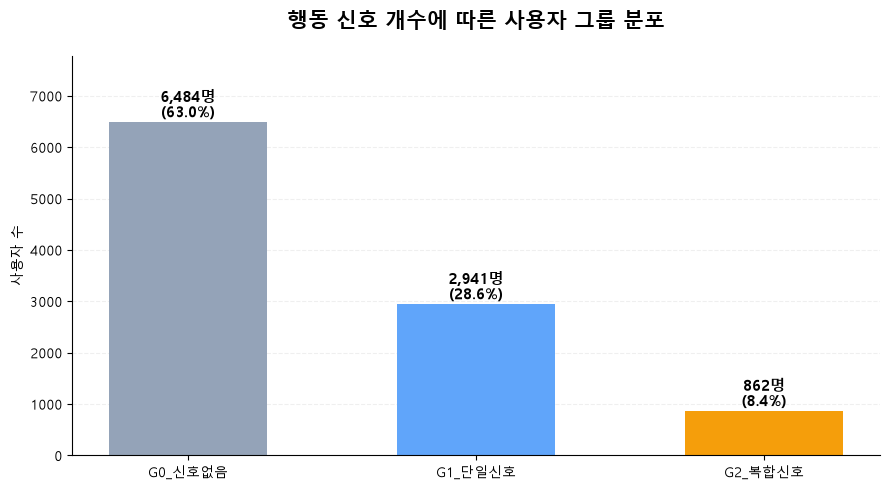

In [129]:
fig, ax = plt.subplots(figsize=(9, 5))

colors = ['#94A3B8', '#60A5FA', '#F59E0B']

bars = ax.bar(
    group_summary['그룹'],
    group_summary['사용자 수'],
    color=colors,
    width=0.55
)

for bar, count, ratio in zip(
    bars,
    group_summary['사용자 수'],
    group_summary['비율(%)']
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 100,
        f'{count:,}명\n({ratio:.1f}%)',
        ha='center',
        fontsize=11,
        fontweight='bold'
    )

ax.set_title(
    '행동 신호 개수에 따른 사용자 그룹 분포',
    fontsize=15,
    fontweight='bold',
    pad=20
)

ax.set_ylabel('사용자 수')
ax.set_ylim(0, group_summary['사용자 수'].max() * 1.2)
ax.grid(axis='y', linestyle='--', alpha=0.2)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

전체 10,287명 중 신호 없음 6,484명(63.0%), 단일 신호 2,941명(28.6%), 복합 신호 862명(8.4%)으로 분류되었다.

복합 신호군은 여러 행동 특성이 동시에 나타나는 사용자로, 후속 분석에서 신호 조합과 행동 패턴을 집중적으로 비교한다. 다만 복합 신호 자체가 실제 허수지원 또는 부적절한 지원을 확정하는 것은 아니다.

# 11. 복합 신호군 행동 조합 분석

## 11-1. 복합 신호 조합 생성

In [130]:
# 행동 지표명 정의
signal_name_map = {
    'volume_score': '대량성',
    'concentration_score': '집중성',
    'diversity_score': '다양성',
    'view_score': '공고탐색성',
    'bookmark_score': '북마크탐색성'
}

# 사용자별 활성화된 행동 신호 조합 생성
def get_signal_combination(row):
    signals = [
        name
        for col, name in signal_name_map.items()
        if row[col] == 1
    ]
    return ' + '.join(signals)

g2['signal_combination'] = g2.apply(
    get_signal_combination,
    axis=1
)

# 신호 조합별 사용자 수 및 비율
combination_summary = (
    g2['signal_combination']
    .value_counts()
    .rename_axis('신호 조합')
    .reset_index(name='사용자 수')
)

combination_summary['비율(%)'] = (
    combination_summary['사용자 수']
    / len(g2) * 100
).round(1)

display(combination_summary.head(15))

,신호 조합,사용자 수,비율(%)
0,다양성 + 공고탐색성,281,32.6
1,집중성 + 공고탐색성,114,13.2
2,대량성 + 공고탐색성,97,11.3
3,대량성 + 다양성,71,8.2
4,대량성 + 집중성 + 공고탐색성,68,7.9
5,대량성 + 집중성,46,5.3
6,대량성 + 다양성 + 공고탐색성,43,5.0
7,대량성 + 집중성 + 다양성 + 공고탐색성,43,5.0
8,대량성 + 집중성 + 다양성,26,3.0
9,공고탐색성 + 북마크탐색성,19,2.2


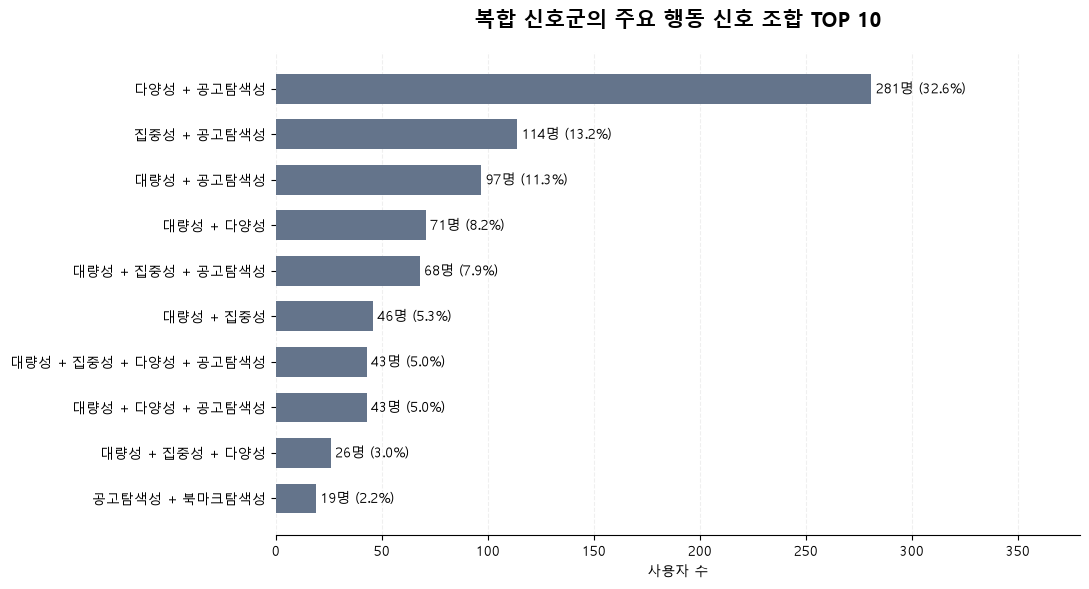

In [131]:
plot_df = combination_summary.head(10).sort_values(
    '사용자 수'
)

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    plot_df['신호 조합'],
    plot_df['사용자 수'],
    color='#64748B',
    height=0.65
)

for bar, count, ratio in zip(
    bars,
    plot_df['사용자 수'],
    plot_df['비율(%)']
):
    ax.text(
        bar.get_width() + 2,
        bar.get_y() + bar.get_height() / 2,
        f'{count:,}명 ({ratio:.1f}%)',
        va='center',
        fontsize=10
    )

ax.set_title(
    '복합 신호군의 주요 행동 신호 조합 TOP 10',
    fontsize=15,
    fontweight='bold',
    pad=18
)

ax.set_xlabel('사용자 수')
ax.set_xlim(0, max(plot_df['사용자 수']) * 1.35)
ax.grid(axis='x', linestyle='--', alpha=0.2)
ax.set_axisbelow(True)
ax.spines[['top', 'right', 'left']].set_visible(False)

plt.tight_layout()
plt.show()

# 12. 복합 신호군 행동 조합 및 주요 유형 분류

**분석 목적**  
2개 이상 신호가 나타난 복합 신호군 **862명(전체의 8.4%)**을 대상으로 신호 결합 구조를 확인하고, 행동 해석이 가능한 주요 유형을 추출한다.

- 5개 신호의 조합은 **22개**로 관찰된다.
- 보고서 기준 주요 유형은 **A 151명 · B 492명 · C 171명 = 814명(복합 신호군의 94.4%)**이다.
- 나머지 **48명(5.6%)**은 북마크탐색성 신호를 포함한 **기타 복합형**으로 유지한다.

> **분류 원칙:** A·B·C는 사용자 가치의 순위가 아니라, 지원행동 신호의 결합 수와 공고탐색성 결합 여부를 설명하는 상호 배타적 유형이다. 전체 862명을 세 유형으로 억지로 배정하지 않는다.

## 12-1. UpSet 형태의 행동 신호 결합 시각화

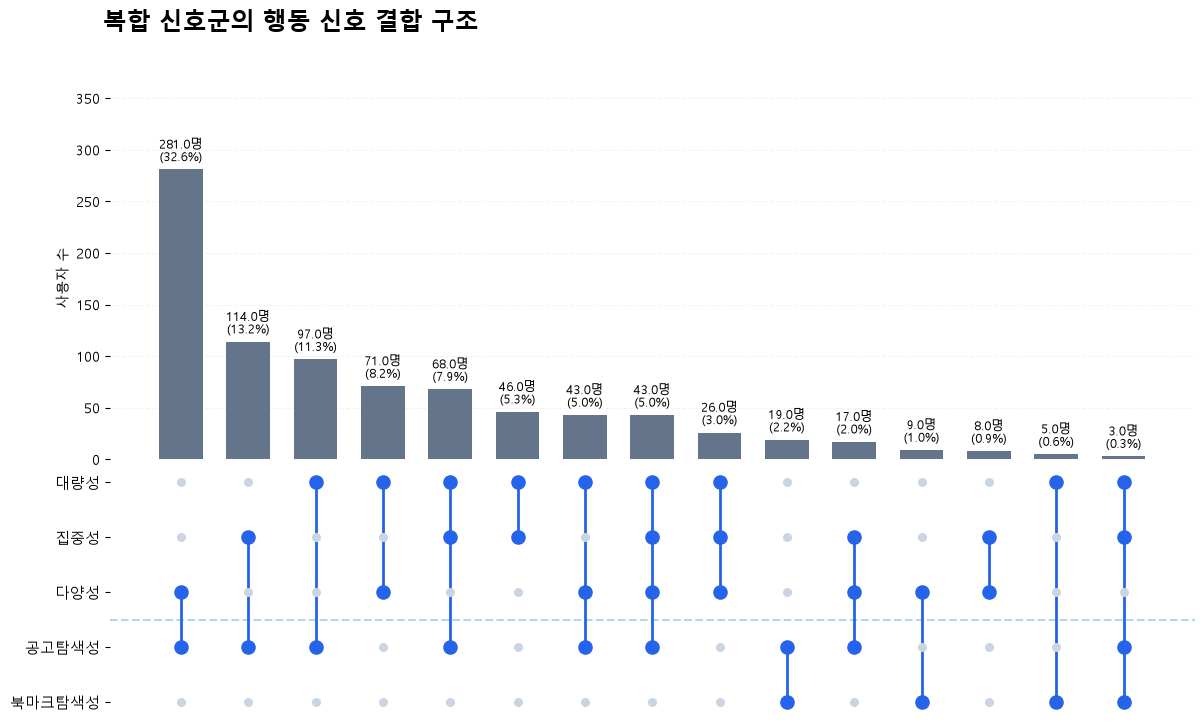

In [132]:
# 복합 신호군의 5개 행동 신호 조합 집계
signal_cols = [
    'volume_score',
    'concentration_score',
    'diversity_score',
    'view_score',
    'bookmark_score'
]

signal_labels = [
    '대량성',
    '집중성',
    '다양성',
    '공고탐색성',
    '북마크탐색성'
]

combo = (
    g2.groupby(signal_cols)
    .size()
    .reset_index(name='users')
    .sort_values('users', ascending=False)
    .reset_index(drop=True)
)

combo['ratio'] = (
    combo['users'] / len(g2) * 100
).round(1)

# 주요 조합 상위 15개 시각화
plot_combo = combo.head(15).reset_index(drop=True)

fig = plt.figure(figsize=(14, 8))
gs = fig.add_gridspec(
    2, 1,
    height_ratios=[3, 2],
    hspace=0.04
)

ax_bar = fig.add_subplot(gs[0])
ax_matrix = fig.add_subplot(gs[1], sharex=ax_bar)

x = np.arange(len(plot_combo))

# 상단: 조합별 사용자 수
ax_bar.bar(
    x,
    plot_combo['users'],
    color='#64748B',
    width=0.65
)

for i, row in plot_combo.iterrows():
    ax_bar.text(
        i,
        row['users'] + max(1, plot_combo['users'].max() * 0.02),
        f'{row["users"]:,}명\n({row["ratio"]:.1f}%)',
        ha='center',
        va='bottom',
        fontsize=9
    )

ax_bar.set_ylabel('사용자 수')
ax_bar.set_ylim(0, plot_combo['users'].max() * 1.25)
ax_bar.tick_params(axis='x', bottom=False, labelbottom=False)
ax_bar.grid(axis='y', linestyle='--', alpha=0.15)
ax_bar.set_axisbelow(True)

# 하단: 신호별 포함 여부
for col_idx, row in plot_combo.iterrows():
    active_rows = []

    for row_idx, signal in enumerate(signal_cols):
        if row[signal] == 1:
            ax_matrix.scatter(
                col_idx, row_idx,
                s=90,
                color='#2563EB',
                zorder=3
            )
            active_rows.append(row_idx)
        else:
            ax_matrix.scatter(
                col_idx, row_idx,
                s=30,
                color='#CBD5E1',
                zorder=2
            )

    if len(active_rows) >= 2:
        ax_matrix.plot(
            [col_idx, col_idx],
            [min(active_rows), max(active_rows)],
            color='#2563EB',
            linewidth=2,
            zorder=1
        )

ax_matrix.set_yticks(range(len(signal_labels)))
ax_matrix.set_yticklabels(signal_labels, fontsize=11)
ax_matrix.set_xticks([])
ax_matrix.invert_yaxis()
ax_matrix.axhline(2.5, linestyle='--', alpha=0.3)

for ax in [ax_bar, ax_matrix]:
    for spine in ['top', 'right', 'bottom', 'left']:
        ax.spines[spine].set_visible(False)

fig.suptitle(
    '복합 신호군의 행동 신호 결합 구조',
    fontsize=17,
    fontweight='bold',
    x=0.12,
    ha='left',
    y=0.99
)

plt.show()

## 12-2. 중복 가능한 행동 조건 탐색

최종 분류 전에 지원행동·공고탐색·북마크탐색 신호가 **서로 어떻게 중첩되는지** 확인한다. 아래 `type_A`, `type_B`, `type_C`는 탐색용 조건으로, **최종 세그먼트 이름과 다르다**.

- `type_A`: 대량성·집중성·다양성 중 2개 이상
- `type_B`: 공고탐색성 + 지원행동 신호 1개 이상
- `type_C`: 북마크탐색성 + 지원행동 신호 1개 이상

최종 A·B·C는 **12-4에서 별도로 정의**한다.

In [133]:
# 지원행동 신호
support_cols = [
    'volume_score',
    'concentration_score',
    'diversity_score'
]

# 지원행동 신호 개수
g2['support_signal_count'] = g2[support_cols].sum(axis=1)

# 기본 행동 유형 정의 (중복 허용)
g2['type_A'] = g2['support_signal_count'] >= 2

g2['type_B'] = (
    (g2['support_signal_count'] >= 1) &
    (g2['view_score'] == 1)
)

g2['type_C'] = (
    (g2['support_signal_count'] >= 1) &
    (g2['bookmark_score'] == 1)
)

# 사용자별 유형 조합 생성
def make_type_combination(row):
    types = []

    if row['type_A']:
        types.append('A')
    if row['type_B']:
        types.append('B')
    if row['type_C']:
        types.append('C')

    return '+'.join(types) if types else '탐색신호만'


g2['behavior_type_combination'] = g2.apply(
    make_type_combination,
    axis=1
)

# 유형 조합별 사용자 수 및 비율
type_combination_summary = (
    g2['behavior_type_combination']
    .value_counts()
    .rename_axis('행동유형 조합')
    .reset_index(name='사용자 수')
)

type_combination_summary['비율(%)'] = (
    type_combination_summary['사용자 수']
    / len(g2) * 100
).round(1)

display(type_combination_summary)

# 상위 3개 조합의 설명 비율
top3_ratio = (
    type_combination_summary.head(3)['사용자 수'].sum()
    / len(g2) * 100
)

print(f'상위 3개 행동유형 조합 비율: {top3_ratio:.1f}%')

,행동유형 조합,사용자 수,비율(%)
0,B,492,57.1
1,A+B,171,19.8
2,A,151,17.5
3,탐색신호만,19,2.2
4,C,14,1.6
5,B+C,6,0.7
6,A+B+C,5,0.6
7,A+C,4,0.5


상위 3개 행동유형 조합 비율: 94.4%


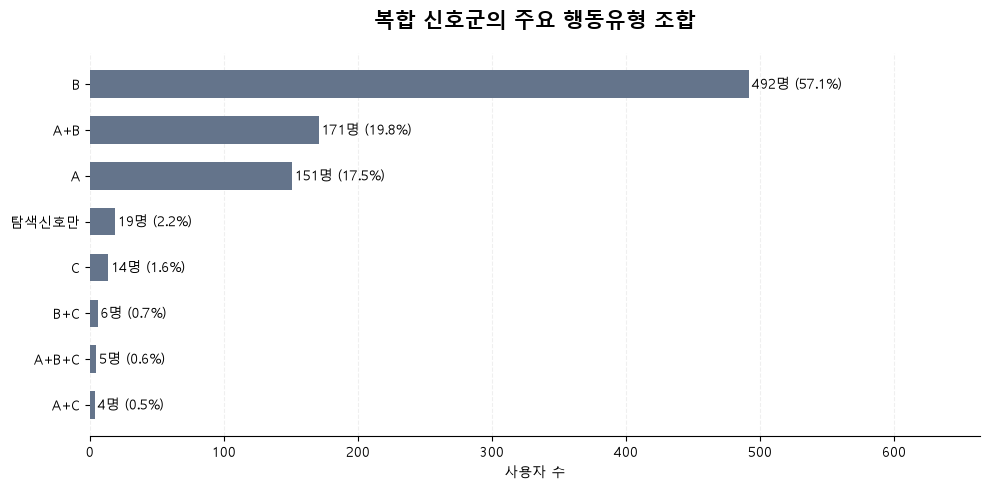

In [134]:
plot_types = (
    type_combination_summary
    .head(10)
    .sort_values('사용자 수')
)

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(
    plot_types['행동유형 조합'],
    plot_types['사용자 수'],
    color='#64748B',
    height=0.6
)

for bar, count, ratio in zip(
    bars,
    plot_types['사용자 수'],
    plot_types['비율(%)']
):
    ax.text(
        bar.get_width() + 2,
        bar.get_y() + bar.get_height() / 2,
        f'{count:,}명 ({ratio:.1f}%)',
        va='center',
        fontsize=10
    )

ax.set_title(
    '복합 신호군의 주요 행동유형 조합',
    fontsize=15,
    fontweight='bold',
    pad=18
)

ax.set_xlabel('사용자 수')
ax.set_xlim(0, plot_types['사용자 수'].max() * 1.35)
ax.grid(axis='x', linestyle='--', alpha=0.2)
ax.set_axisbelow(True)
ax.spines[['top', 'right', 'left']].set_visible(False)

plt.tight_layout()
plt.show()

### 12-2 결과 해석 | 주요 결합 패턴

| 탐색용 조합 | 사용자 수 | 복합 신호군 내 비율 | 의미 |
|---|---:|---:|---|
| B | 492명 | 57.1% | 공고탐색성 + 지원행동 신호 1개 |
| A+B | 171명 | 19.8% | 지원행동 신호 2개 이상 + 공고탐색성 |
| A | 151명 | 17.5% | 지원행동 신호 2개 이상, 탐색 신호 없음 |
| 그 외 | 48명 | 5.6% | 북마크탐색성 포함 복합 조합 |

**핵심 결과:** 위 세 조합이 **814명(94.4%)**을 차지한다. 이 조합을 각각 최종 **B·C·A**로 대응시키고, 북마크탐색성이 포함된 48명은 기타 복합형으로 분리한다.  
※ 여기의 `A+B`는 **탐색용 플래그의 교집합**이며 최종 A와 B에 중복 배정한다는 뜻이 아니다.

## 12-4. 보고서 기준 최종 유형 분류

| 유형 | 사용자 정의 | 사용자 수 | 비율(G2 기준) |
|---|---|---:|---:|
| **A · 지원행동 복합형** | 지원행동 신호 **2개 이상** + 공고탐색성 0 + 북마크탐색성 0 | **151명** | 17.5% |
| **B · 공고탐색 결합형** | 지원행동 신호 **정확히 1개** + 공고탐색성 1 + 북마크탐색성 0 | **492명** | 57.1% |
| **C · 고복합 행동형** | 지원행동 신호 **2개 이상** + 공고탐색성 1 + 북마크탐색성 0 | **171명** | 19.8% |
| **기타 복합형** | 위 유형에 속하지 않는 북마크탐색성 포함 조합 | **48명** | 5.6% |

**선정 근거:** 신호 조합별 빈도와 해석 가능성을 고려해 주요 세 유형을 정의한다. **A와 C는 지원행동 신호가 복합적으로 나타난다는 공통점**이 있으므로, 실제 지원·탐색 행동에서 충분히 구분되는지는 별도로 검토한다. 북마크탐색성은 버리는 지표가 아니라, 소수의 기타 복합형을 식별하는 데 사용된다.

In [135]:
# 주요 유형 814명 + 기타 복합형 48명
support_cols = ['volume_score', 'concentration_score', 'diversity_score']
score_cols = support_cols + ['view_score', 'bookmark_score']
g2['support_signal_count'] = g2[support_cols].sum(axis=1)
g2['total_signal_count'] = g2[score_cols].sum(axis=1)

assert g2['user_uuid'].is_unique, 'G2 사용자 중복'
assert len(g2) == 862, 'G2 인원 확인 필요'
assert g2['total_signal_count'].ge(2).all(), 'G2에 2점 미만 포함'

# 북마크 탐색성 신호가 있는 사용자는 기타 복합형으로 별도 유지
conditions = [
    g2['bookmark_score'].eq(0) & g2['view_score'].eq(0) & g2['support_signal_count'].ge(2),
    g2['bookmark_score'].eq(0) & g2['view_score'].eq(1) & g2['support_signal_count'].eq(1),
    g2['bookmark_score'].eq(0) & g2['view_score'].eq(1) & g2['support_signal_count'].ge(2)
]
choices = ['A_지원행동복합형', 'B_공고탐색결합형', 'C_고복합행동형']
g2['final_segment'] = np.select(conditions, choices, default='기타_복합형')

segment_order_g2 = choices + ['기타_복합형']
segment_summary = (
    g2['final_segment'].value_counts()
    .reindex(segment_order_g2, fill_value=0)
    .rename_axis('세그먼트').reset_index(name='사용자 수')
)
segment_summary['비율(%)'] = (segment_summary['사용자 수'] / len(g2) * 100).round(1)
display(segment_summary)

expected = dict(zip(segment_order_g2, [151, 492, 171, 48]))
actual = g2['final_segment'].value_counts().to_dict()
assert all(actual.get(k, 0) == v for k, v in expected.items()), f'보고서 5-4 불일치: {actual}'
assert (g2.loc[g2['final_segment'].eq('기타_복합형'), 'bookmark_score'] == 1).all()
print('보고서 5장 최종 유형 검증 완료: A 151 / B 492 / C 171 / 기타 48')

,세그먼트,사용자 수,비율(%)
0,A_지원행동복합형,151,17.5
1,B_공고탐색결합형,492,57.1
2,C_고복합행동형,171,19.8
3,기타_복합형,48,5.6


보고서 5장 최종 유형 검증 완료: A 151 / B 492 / C 171 / 기타 48


## 12-5. 전체 사용자 최종 세그먼트 통합

In [136]:
# 보고서 5-4: 전체 10,287명 기준 최종 유형 연결
final_user_scores = final_user_scores.drop(columns=['final_segment', 'behavior_type'], errors='ignore')
final_user_scores = final_user_scores.merge(
    g2[['user_uuid', 'final_segment']], on='user_uuid', how='left', validate='one_to_one'
)
final_user_scores['final_segment'] = np.select(
    [final_user_scores['total_score'].eq(0), final_user_scores['total_score'].eq(1)],
    ['G0_신호없음', 'G1_단일신호'],
    default=final_user_scores['final_segment'].fillna('미분류')
)
segment_order = [
    'G0_신호없음', 'G1_단일신호', 'A_지원행동복합형',
    'B_공고탐색결합형', 'C_고복합행동형', '기타_복합형'
]
final_segment_summary = (
    final_user_scores['final_segment'].value_counts()
    .reindex(segment_order, fill_value=0)
    .rename_axis('세그먼트').reset_index(name='사용자 수')
)
final_segment_summary['전체 비율(%)'] = (
    final_segment_summary['사용자 수'] / len(final_user_scores) * 100
).round(2)
display(final_segment_summary)

,세그먼트,사용자 수,전체 비율(%)
0,G0_신호없음,6484,63.03
1,G1_단일신호,2941,28.59
2,A_지원행동복합형,151,1.47
3,B_공고탐색결합형,492,4.78
4,C_고복합행동형,171,1.66
5,기타_복합형,48,0.47


## 12-6. 최종 세그먼트 검증

In [137]:
# 보고서 4장·5장과 전체 인원 일치 검증
assert len(final_user_scores) == 10287
assert final_user_scores['user_uuid'].is_unique
assert final_segment_summary['사용자 수'].sum() == 10287
assert final_user_scores['final_segment'].isin(segment_order).all()
assert (final_user_scores.loc[final_user_scores['total_score'].eq(0), 'final_segment'] == 'G0_신호없음').all()
assert (final_user_scores.loc[final_user_scores['total_score'].eq(1), 'final_segment'] == 'G1_단일신호').all()
expected_all = [6484, 2941, 151, 492, 171, 48]
assert final_segment_summary['사용자 수'].tolist() == expected_all, '보고서 그룹별 인원과 불일치'
print('보고서 기준 전체 사용자 유형 검증 완료')

보고서 기준 전체 사용자 유형 검증 완료


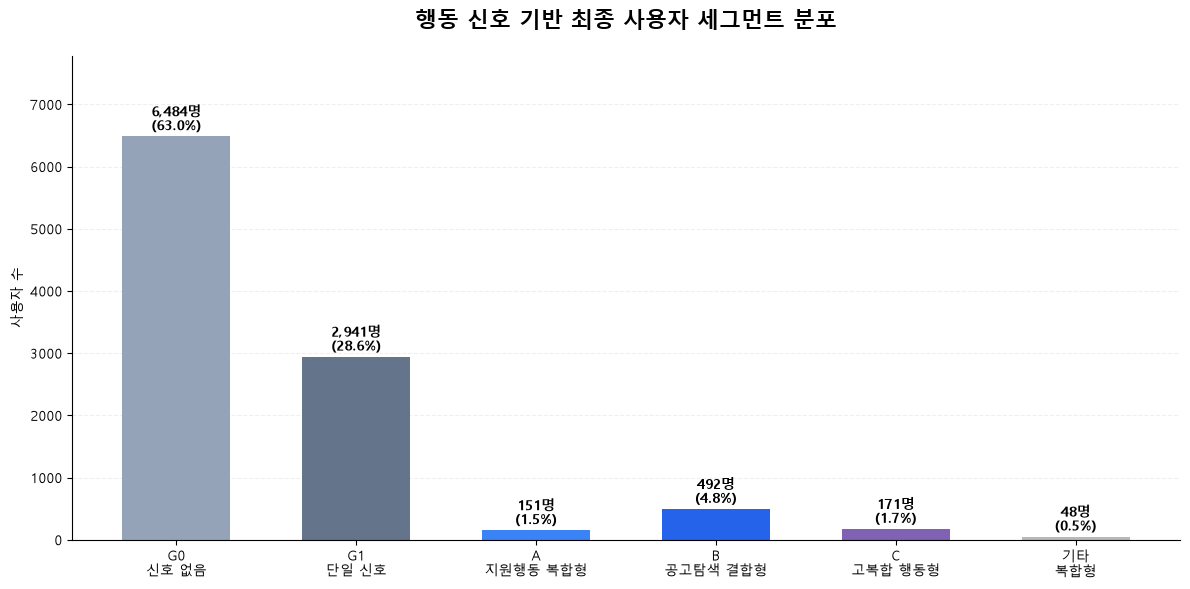

In [138]:
# 최종 세그먼트 분포 시각화
plot_df = final_segment_summary.copy()

colors = [
    '#94A3B8',
    '#64748B',
    '#3B82F6',
    '#2563EB',
    '#8062B4',
    '#B8B8B8'
]

fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.bar(
    plot_df['세그먼트'],
    plot_df['사용자 수'],
    color=colors,
    width=0.6
)

# 사용자 수와 비율 표시
for bar, count, ratio in zip(
    bars,
    plot_df['사용자 수'],
    plot_df['전체 비율(%)']
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 100,
        f'{count:,}명\n({ratio:.1f}%)',
        ha='center',
        fontsize=10,
        fontweight='bold'
    )

ax.set_title(
    '행동 신호 기반 최종 사용자 세그먼트 분포',
    fontsize=16,
    fontweight='bold',
    pad=20
)

ax.set_ylabel('사용자 수')
ax.set_xlabel('')
ax.set_ylim(0, plot_df['사용자 수'].max() * 1.2)

ax.set_xticks(range(len(plot_df)))
ax.set_xticklabels(
    [
        'G0\n신호 없음',
        'G1\n단일 신호',
        'A\n지원행동 복합형',
        'B\n공고탐색 결합형',
        'C\n고복합 행동형',
        '기타\n복합형'
    ],
    fontsize=10
)

ax.grid(axis='y', linestyle='--', alpha=0.2)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

### 12장 핵심 결과 | 사용자 유형 분포

- **전체 지원자 10,287명:** G0 **6,484명(63.0%)**, G1 **2,941명(28.6%)**, 복합 신호군 **862명(8.4%)**.
- **복합 신호군 862명:** A **151명**, B **492명**, C **171명**, 기타 복합형 **48명**.
- **주요 세 유형 814명(94.4%)**을 대상으로 행동 차이를 집중 비교하되, 기타 48명은 분석 모집단에서 누락하지 않고 별도 보존한다.

**해석:** 신호의 개수와 조합은 관찰된 행동 특성을 나타낼 뿐, 허수지원 여부나 채용 적합성을 확정하지 않는다.

## 12-7. 최종 사용자 마스터 테이블 저장

5개 행동 지표의 점수와 사용자 그룹, 최종 세그먼트를 통합한
사용자 단위 마스터 테이블을 저장한다.

이후 사용자 유형별 행동 특성 비교 분석의 기준 테이블로 활용한다.

In [139]:
# 최종 사용자 마스터 테이블
user_master_final = final_user_scores.copy()

# 주요 컬럼 순서 정리
main_cols = [
    'user_uuid',
    'volume_score',
    'concentration_score',
    'diversity_score',
    'view_score',
    'bookmark_score',
    'total_score',
    'analysis_group',
    'final_segment'
]

# 결측 여부 등 추가 컬럼 유지
other_cols = [
    col for col in user_master_final.columns
    if col not in main_cols
]

user_master_final = user_master_final[main_cols + other_cols]

# 데이터 검증
assert len(user_master_final) == 10287
assert user_master_final['user_uuid'].is_unique
assert user_master_final['final_segment'].notna().all()

# CSV 저장
user_master_final.to_csv(
    'data/final/user_master_final.csv',
    index=False,
    encoding='utf-8-sig'
)

print(f'저장 완료: {len(user_master_final):,}명')
print(f'컬럼 수: {user_master_final.shape[1]}개')

display(user_master_final.head())

저장 완료: 10,287명
컬럼 수: 14개


,user_uuid,volume_score,concentration_score,diversity_score,view_score,bookmark_score,total_score,analysis_group,final_segment,volume_null,concentration_null,diversity_null,view_null,bookmark_null
0,2ece8d7d-79b6-4522-928b-8dbae8843fab,1,0,1,0,0,2,G2_복합신호,A_지원행동복합형,0,0,0,0,0
1,24ffac10-a46e-4adb-af66-0074d259c809,0,0,0,0,0,0,G0_신호없음,G0_신호없음,0,0,0,0,0
2,40196d59-ab7c-4951-8a5b-eb87aac0a08b,0,0,1,0,0,1,G1_단일신호,G1_단일신호,0,0,0,0,0
3,3e20b9ee-48bc-46cd-9713-d629f0a51b59,0,0,0,0,0,0,G0_신호없음,G0_신호없음,0,0,0,0,0
4,2bc97037-032e-4137-93d4-feebaa1c2524,0,0,0,0,0,0,G0_신호없음,G0_신호없음,0,0,0,0,0


In [140]:
# user_master_final = pd.read_csv('data/final/user_master_final.csv')

# 13. 최종 사용자 유형별 행동 특성 비교

## 13-0. 공통 그룹 기준·행동 피처·분석 함수

지원·공고 상세조회·북마크 행동을 **사용자 단위로 한 번만 통합**합니다. 이후 그룹명과 행동 유형만 변경해 요약표·시각화를 재사용합니다. 기존 지표 정의와 분모(전체 지원 건수)를 유지합니다.

In [141]:
# 최종 사용자 그룹 기준 테이블
group_master = user_master_final[[
    'user_uuid',
    'analysis_group',
    'final_segment'
]].copy()

# 그룹별 사용자 수 확인
group_summary = (
    group_master
    .groupby(['analysis_group', 'final_segment'])
    .agg(users=('user_uuid', 'nunique'))
    .reset_index()
)

display(group_summary)

# 검증
assert group_master['user_uuid'].is_unique
assert len(group_master) == 10287

,analysis_group,final_segment,users
0,G0_신호없음,G0_신호없음,6484
1,G1_단일신호,G1_단일신호,2941
2,G2_복합신호,A_지원행동복합형,151
3,G2_복합신호,B_공고탐색결합형,492
4,G2_복합신호,C_고복합행동형,171
5,G2_복합신호,기타_복합형,48


### 13-0-1. 전체 사용자 행동 피처 생성

In [142]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 새 최종 세그먼트 라벨 적용
SEGMENTS = {
    'G0': 'G0_신호없음', 'G1': 'G1_단일신호',
    'A': 'A_지원행동복합형', 'B': 'B_공고탐색결합형',
    'C': 'C_고복합행동형', '기타': '기타_복합형'
}

# 공통 지원 행동: 기존 13-1의 cdate_kst와 동일한 시간대 처리
_app = app_df[['user_uuid', 'cdate_kst']].copy()
_app['cdate_kst'] = pd.to_datetime(_app['cdate_kst'], errors='coerce', utc=True).dt.tz_convert('Asia/Seoul')
_app['apply_date'] = _app['cdate_kst'].dt.date
_apply = _app.groupby('user_uuid').agg(
    total_applications=('user_uuid', 'size'),
    active_days=('apply_date', 'nunique'),
    first_apply=('cdate_kst', 'min'), last_apply=('cdate_kst', 'max')
).reset_index()
_apply['activity_span_days'] = (_apply['last_apply'] - _apply['first_apply']).dt.total_seconds() / 86400 + 1
_apply['applications_per_active_day'] = _apply['total_applications'] / _apply['active_days']

# 공고 상세조회: 전체 로그 중 해당 URL만 집계
_view = (log_df.loc[log_df['URL'].eq('jobs/id/id_title')]
         .groupby('user_uuid').size().rename('job_view_count').reset_index())

# 북마크: 이미 생성된 사용자별 분석 결과 재사용
_bookmark_cols = [
    'user_uuid', '고유북마크공고수', '북마크_추가횟수',
    '북마크_취소횟수', '북마크_총액션횟수'
]
_bookmark = bookmark_analysis_df[_bookmark_cols].copy()

user_behavior = (user_master_final[['user_uuid', 'analysis_group', 'final_segment']]
    .merge(_apply, on='user_uuid', how='left', validate='one_to_one')
    .merge(_view, on='user_uuid', how='left', validate='one_to_one')
    .merge(_bookmark, on='user_uuid', how='left', validate='one_to_one'))
_count_cols = ['job_view_count', '고유북마크공고수', '북마크_추가횟수', '북마크_취소횟수', '북마크_총액션횟수']
user_behavior[_count_cols] = user_behavior[_count_cols].fillna(0)
user_behavior['views_per_application'] = user_behavior['job_view_count'] / user_behavior['total_applications']
user_behavior['bookmarks_per_application'] = user_behavior['고유북마크공고수'] / user_behavior['total_applications']
user_behavior['has_bookmark'] = user_behavior['고유북마크공고수'].gt(0)

assert len(user_behavior) == 10287 and user_behavior['user_uuid'].is_unique
assert user_behavior['total_applications'].notna().all()
print('공통 사용자 피처:', user_behavior.shape, '| 중복 사용자:', user_behavior['user_uuid'].duplicated().sum())
display(user_behavior.head())

공통 사용자 피처: (10287, 17) | 중복 사용자: 0


,user_uuid,analysis_group,final_segment,total_applications,active_days,first_apply,last_apply,activity_span_days,applications_per_active_day,job_view_count,고유북마크공고수,북마크_추가횟수,북마크_취소횟수,북마크_총액션횟수,views_per_application,bookmarks_per_application,has_bookmark
0,2ece8d7d-79b6-4522-928b-8dbae8843fab,G2_복합신호,A_지원행동복합형,5616,666,2022-01-01 13:49:55+09:00,2023-12-31 23:28:28+09:00,730.401771,8.432432,0.0,0,0,0,0,0.0000,0.0000,False
1,24ffac10-a46e-4adb-af66-0074d259c809,G0_신호없음,G0_신호없음,2,2,2022-05-26 16:22:33+09:00,2022-12-07 19:19:25+09:00,196.122824,1.000000,54.0,10,9,0,9,27.0000,5.0000,True
2,40196d59-ab7c-4951-8a5b-eb87aac0a08b,G1_단일신호,G1_단일신호,16,15,2022-12-15 23:35:55+09:00,2023-04-07 21:47:10+09:00,113.924479,1.066667,245.0,1,1,0,1,15.3125,0.0625,True
3,3e20b9ee-48bc-46cd-9713-d629f0a51b59,G0_신호없음,G0_신호없음,1,1,2023-06-12 01:19:59+09:00,2023-06-12 01:19:59+09:00,1.000000,1.000000,1.0,0,0,0,0,1.0000,0.0000,False
4,2bc97037-032e-4137-93d4-feebaa1c2524,G0_신호없음,G0_신호없음,1,1,2022-10-24 19:50:13+09:00,2022-10-24 19:50:13+09:00,1.000000,1.000000,301.0,10,17,10,27,301.0000,10.0000,True


### 13-0-2. 그룹 비교·요약표·시각화 함수

In [143]:
# 기존 노트북의 요약표와 동일한 정의: 사용자별 비율을 먼저 계산한 뒤 평균·중앙값 산출
AGGS = {
    'application': {
        'mean_applications': ('total_applications', 'mean'),
        'median_applications': ('total_applications', 'median'),
        'p75_applications': ('total_applications', lambda x: x.quantile(.75)),
        'p90_applications': ('total_applications', lambda x: x.quantile(.90)),
        'median_active_days': ('active_days', 'median'),
        'median_activity_span': ('activity_span_days', 'median'),
        'median_applications_per_day': ('applications_per_active_day', 'median')
    },
    'view': {
        'mean_views': ('job_view_count', 'mean'),
        'median_views': ('job_view_count', 'median'),
        'p75_views': ('job_view_count', lambda x: x.quantile(.75)),
        'p90_views': ('job_view_count', lambda x: x.quantile(.90)),
        'median_views_per_application': ('views_per_application', 'median'),
        'mean_views_per_application': ('views_per_application', 'mean'),
        'users_with_views': ('job_view_count', lambda x: x.gt(0).sum())
    },
    'bookmark': {
        'mean_bookmarks': ('고유북마크공고수', 'mean'),
        'median_bookmarks': ('고유북마크공고수', 'median'),
        'p75_bookmarks': ('고유북마크공고수', lambda x: x.quantile(.75)),
        'p90_bookmarks': ('고유북마크공고수', lambda x: x.quantile(.90)),
        'median_bookmarks_per_application': ('bookmarks_per_application', 'median'),
        'mean_bookmarks_per_application': ('bookmarks_per_application', 'mean'),
        'bookmark_users': ('has_bookmark', 'sum'),
        'median_add': ('북마크_추가횟수', 'median'),
        'median_cancel': ('북마크_취소횟수', 'median'),
        'median_actions': ('북마크_총액션횟수', 'median')
    }
}

PLOT_METRICS = {
    'application': [('median_applications', '지원 건수 중앙값', '건'),
                    ('median_applications_per_day', '활동일당 지원 횟수 중앙값', '회')],
    'view': [('median_views', '공고 상세조회 수 중앙값', '회'),
             ('median_views_per_application', '지원당 공고 조회 수 중앙값', '회')],
    'bookmark': [('median_bookmarks', '고유 북마크 공고 수 중앙값', '개'),
                 ('median_bookmarks_per_application', '지원당 북마크 공고 수 중앙값', '개'),
                 ('bookmark_user_ratio', '북마크 이용률', '%')]
}

def get_group_users(target, baseline='G0'):
    labels = [SEGMENTS[baseline], SEGMENTS[target]]
    result = user_behavior.loc[user_behavior['final_segment'].isin(labels)].copy()
    assert result['final_segment'].nunique() == 2, f'그룹 누락: {labels}'
    return result

def summarize_behavior(target, behavior, baseline='G0'):
    if behavior not in AGGS:
        raise ValueError('behavior: application / view / bookmark')
    df = get_group_users(target, baseline)
    result = (df.groupby('final_segment').agg(
        users=('user_uuid', 'nunique'), **AGGS[behavior]
    ).reindex([SEGMENTS[baseline], SEGMENTS[target]]))
    if behavior == 'bookmark':
        result['bookmark_user_ratio'] = result['bookmark_users'] / result['users'] * 100
    return result.round(2)

def plot_behavior(summary, target, behavior, baseline='G0'):
    metrics = PLOT_METRICS[behavior]
    fig, axes = plt.subplots(1, len(metrics), figsize=(6 * len(metrics), 5.1), squeeze=False)
    for ax, (column, label, unit) in zip(axes.flat, metrics):
        values = summary[column].to_numpy(dtype=float)
        bars = ax.bar([baseline, target], values, color=['#B5C0CC', '#3579BF'], width=.48)
        upper = max(values) if max(values) > 0 else 1
        for bar, value in zip(bars, values):
            ax.text(bar.get_x() + bar.get_width()/2, value + upper*.04,
                    f'{value:,.1f}{unit}', ha='center', fontsize=11, fontweight='bold')
        ax.set_ylim(0, upper * 1.3)
        ax.set_title(label, fontsize=12, fontweight='bold', pad=16)
        ax.grid(axis='y', alpha=.16)
        ax.set_axisbelow(True)
        ax.spines[['top', 'right']].set_visible(False)
    fig.suptitle(f'{baseline} vs {target} | {dict(application="지원", view="공고탐색", bookmark="북마크")[behavior]} 행동 비교',
                 fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()
    return fig

def run_behavior(target, behavior, baseline='G0', plot=True):
    summary = summarize_behavior(target, behavior, baseline)
    display(summary)
    if plot:
        plot_behavior(summary, target, behavior, baseline)
    return summary


## 13-1. G1 | 단일 신호 사용자 행동 분석

**분석 목적**

- G0를 기준으로 G1의 지원·공고탐색·북마크 행동을 동일한 집계 기준으로 비교합니다.
- 단일 행동 신호의 구성과 공고탐색성 신호의 반복성을 검증하여 사용자 특성을 해석합니다.
- 최종 유형명과 그룹 간 상대적 위치는 전체 그룹 종합 비교에서 검토합니다.

### 13-1-0. 비교 대상 사용자 확인

공통 사용자 행동 테이블에서 G0와 G1의 사용자 수를 확인합니다.

In [144]:
g01_users = get_group_users('G1')[['user_uuid', 'analysis_group', 'final_segment']]
display(g01_users.groupby('final_segment')['user_uuid'].nunique().rename('users').to_frame())


,users
final_segment,
G0_신호없음,6484
G1_단일신호,2941


### 13-1-1. G0 vs G1 | 지원 행동 비교

사용자별 지원 건수와 실제 지원 활동일수·활동기간·활동일당 지원 횟수를 비교합니다.

,users,mean_applications,median_applications,p75_applications,p90_applications,median_active_days,median_activity_span,median_applications_per_day
final_segment,,,,,,,,
G0_신호없음,6484,4.40,2.0,5.0,11.0,1.0,1.08,1.00
G1_단일신호,2941,8.51,4.0,10.0,19.0,3.0,17.81,1.53


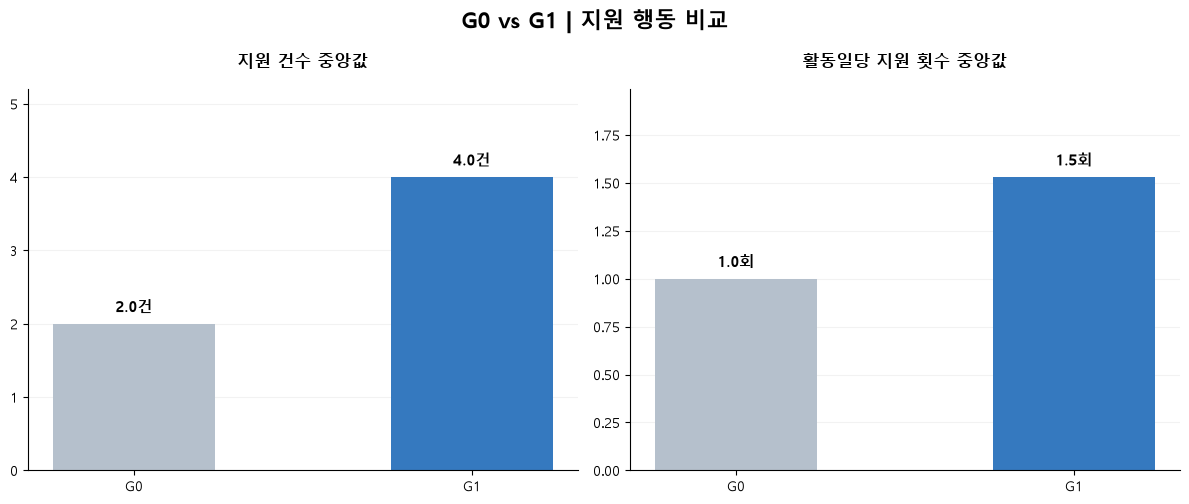

In [145]:
g01_apply_summary = run_behavior('G1', 'application')


### T검정

In [146]:
import pandas as pd
from scipy import stats

g0_apps = user_behavior[user_behavior['final_segment'] == 'G0_신호없음']['total_applications']
g1_apps = user_behavior[user_behavior['final_segment'] == 'G1_단일신호']['total_applications']

t_stat, p_value = stats.ttest_ind(g0_apps, g1_apps, equal_var=False)

result_df = pd.DataFrame({
    '비교 그룹': ['G0 (신호 없음) vs G1 (단일 신호)'],
    '검정 방법': ["Welch's t-test"],
    't-통계량': [f"{t_stat:.4f}"],
    'p-value': [f"{p_value:.5e}"],
    '유의성 판정': ['유의함 (p < 0.05)' if p_value < 0.05 else '유의하지 않음']
})

# 표 출력
display(result_df)

,비교 그룹,검정 방법,t-통계량,p-value,유의성 판정
0,G0 (신호 없음) vs G1 (단일 신호),Welch's t-test,-16.4225,1.73526e-58,유의함 (p < 0.05)


G1 그룹이 G0 그룹에 비해 통계적으로 매우 유의미하게 더 많은 지원 행동을 보인다는 점이 객관적으로 입증되었습니다.

### 13-1-2. G0 vs G1 | 공고탐색 행동 비교

공고 상세조회 건수와 사용자별 지원당 공고 조회 수를 비교합니다.

,users,mean_views,median_views,p75_views,p90_views,median_views_per_application,mean_views_per_application,users_with_views
final_segment,,,,,,,,
G0_신호없음,6484,82.62,34.0,92.0,204.0,12.0,27.35,6343
G1_단일신호,2941,101.12,47.0,115.0,245.0,9.0,20.29,2935


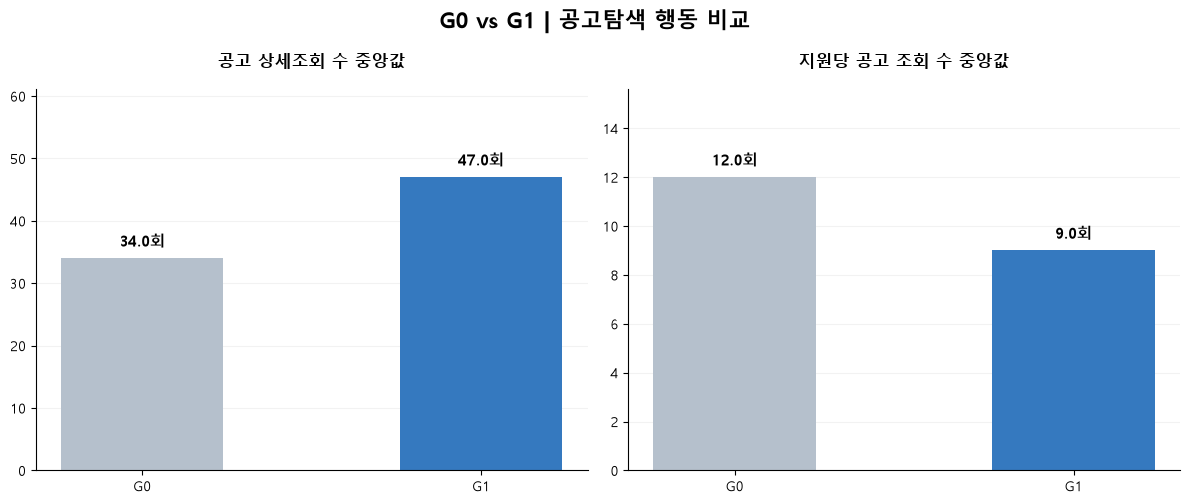

In [147]:
g01_view_summary = run_behavior('G1', 'view')


In [ ]:
import pandas as pd
from scipy import stats

g0_views = user_behavior[user_behavior['final_segment'] == 'G0_신호없음']['job_view_count']
g1_views = user_behavior[user_behavior['final_segment'] == 'G1_단일신호']['job_view_count']

t_stat, p_value = stats.ttest_ind(g0_views, g1_views, equal_var=False)

result_df = pd.DataFrame({
    '비교 그룹': ['G0 (신호 없음) vs G1 (단일 신호)'],
    '비교 지표': ['공고 상세조회 횟수'],
    '검정 방법': ["Welch's t-test"],
    't-통계량': [f"{t_stat:.4f}"],
    'p-value': [f"{p_value:.5e}"],
    '유의성 판정': ['유의함 (p < 0.05)' if p_value < 0.05 else '유의하지 않음']
})

display(result_df)

,비교 그룹,비교 지표,검정 방법,t-통계량,p-value,유의성 판정
0,G0 (신호 없음) vs G1 (단일 신호),공고 상세조회 횟수,Welch's t-test,-5.0831,3.84259e-07,유의함 (p < 0.05)


G1 그룹이 G0 그룹에 비해 통계적으로 매우 유의미하게 더 많은 공고를 탐색한다는 점이 객관적으로 입증되었습니다.

### 13-1-3. G0 vs G1 | 북마크 행동 비교

고유 북마크 공고 수, 사용자별 지원당 북마크 수 및 북마크 이용률을 비교합니다.

,users,mean_bookmarks,median_bookmarks,p75_bookmarks,p90_bookmarks,median_bookmarks_per_application,mean_bookmarks_per_application,bookmark_users,median_add,median_cancel,median_actions,bookmark_user_ratio
final_segment,,,,,,,,,,,,
G0_신호없음,6484,4.71,1.0,5.0,14.0,0.18,1.76,3444,0.0,0.0,0.0,53.12
G1_단일신호,2941,7.12,1.0,7.0,19.0,0.17,1.74,1659,1.0,0.0,1.0,56.41


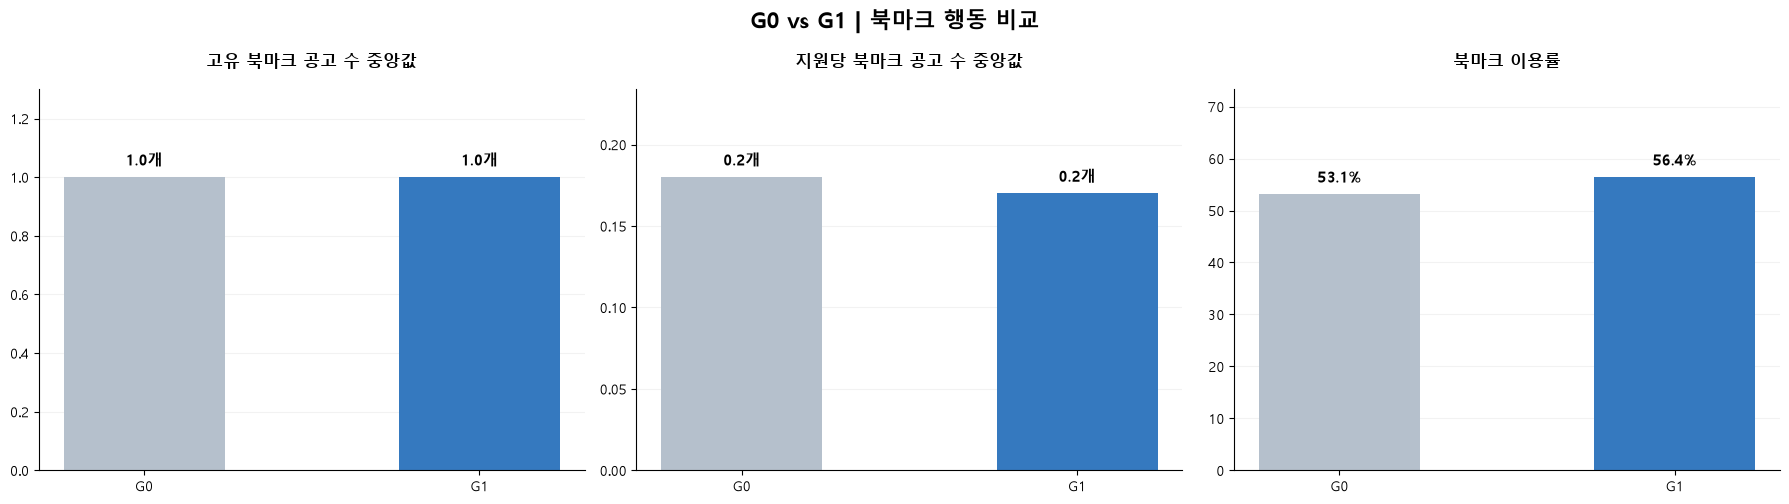

In [148]:
g01_bookmark_summary = run_behavior('G1', 'bookmark')


### 13-1-4. G1 단일 행동 신호 구성 분석

**분석 목적**

- G1 사용자에게 나타난 5개 행동 신호의 구성 비율을 확인한다.
- G1을 대표하는 행동 특성이 무엇인지 파악한다.
- 앞서 분석한 지원·탐색 행동 차이와 연결하여 사용자 유형을 정의하고, 개선 방향을 구체화한다.

In [149]:
# G1 사용자 추출
g1_users = user_master_final[
    user_master_final['final_segment'] == 'G1_단일신호'
].copy()

# 행동 신호 컬럼
score_cols = [
    'volume_score',
    'concentration_score',
    'diversity_score',
    'view_score',
    'bookmark_score'
]

# 단일 신호 구성 확인
g1_signal_summary = (
    g1_users[score_cols]
    .sum()
    .rename('users')
    .to_frame()
)

g1_signal_summary['ratio'] = (
    g1_signal_summary['users']
    / len(g1_users) * 100
).round(1)

# 한글 지표명
g1_signal_summary.index = [
    '대량성',
    '집중성',
    '다양성',
    '공고탐색성',
    '북마크탐색성'
]

g1_signal_summary = (
    g1_signal_summary
    .sort_values('users', ascending=False)
)

display(g1_signal_summary)

# 검증
assert len(g1_users) == 2941
assert (g1_users[score_cols].sum(axis=1) == 1).all()
assert g1_signal_summary['users'].sum() == 2941

,users,ratio
공고탐색성,2099,71.4
다양성,561,19.1
대량성,134,4.6
집중성,75,2.6
북마크탐색성,72,2.4


### 13-1-5. 공고탐색성 신호의 반복성 검증

**분석 목적**

기존 공고탐색성 지표는 지원 직전 30분 이내 공고 조회 기록이 확인된 지원 건을 대상으로, 사용자별 평균 시간 간격이 3분 이하인 경우 1점을 부여하였다.

그러나 일부 지원 건에서만 짧은 간격이 관찰되어도 해당 기준을 충족할 수 있다는 한계가 있다.

따라서 전체 지원 건수 대비 조회-지원 연결 비율과 3분 이내 조회-지원 연결 비율을 확인하여, 짧은 시간 간격이 사용자의 지원 행동에서 얼마나 반복적으로 나타나는지 검증한다.

#### 1) 사용자별 조회-지원 연결 비율 계산

- 30분 이내 연결 비율 = 30분 이내 조회 기록이 연결된 지원 건수 / 전체 지원 건수

- 3분 이내 연결 비율 = 3분 이내 조회 기록이 연결된 지원 건수 / 전체 지원 건수

In [150]:
# 1. 전체 지원 건수
user_apply_counts = (
    app_view_base.groupby('user_uuid')
    .agg(total_applications=('application_uuid', 'nunique'))
    .reset_index()
)

# 2. 30분 이내 연결된 지원 건수
user_30min_counts = (
    valid_view_apply.groupby('user_uuid')
    .agg(matched_30min=('application_uuid', 'nunique'))
    .reset_index()
)

# 3. 3분 이내 연결된 지원 건수
user_3min_counts = (
    valid_view_apply[
        valid_view_apply['view_to_apply_sec'].between(0, 180)
    ]
    .groupby('user_uuid')
    .agg(matched_3min=('application_uuid', 'nunique'))
    .reset_index()
)

# 4. 사용자별 통합
view_repeat_features = (
    user_apply_counts
    .merge(user_30min_counts, on='user_uuid', how='left')
    .merge(user_3min_counts, on='user_uuid', how='left')
    .fillna({'matched_30min': 0, 'matched_3min': 0})
)

# 5. 비율 계산
view_repeat_features['match_30min_ratio'] = (
    view_repeat_features['matched_30min']
    / view_repeat_features['total_applications']
)

view_repeat_features['match_3min_ratio'] = (
    view_repeat_features['matched_3min']
    / view_repeat_features['total_applications']
)

# 6. 기존 사용자 그룹 및 공고탐색성 점수 연결
view_repeat_features = view_repeat_features.merge(
    user_master_final[
        ['user_uuid', 'final_segment', 'view_score']
    ],
    on='user_uuid',
    how='left',
    validate='one_to_one'
)

print('전체 사용자 수:', len(view_repeat_features))
print('중복 사용자 수:', view_repeat_features['user_uuid'].duplicated().sum())
print('30분 연결 건수:', int(view_repeat_features['matched_30min'].sum()))
print('3분 연결 건수:', int(view_repeat_features['matched_3min'].sum()))

display(view_repeat_features.head())

전체 사용자 수: 10287
중복 사용자 수: 0
30분 연결 건수: 70963
3분 연결 건수: 45870


,user_uuid,total_applications,matched_30min,matched_3min,match_30min_ratio,match_3min_ratio,final_segment,view_score
0,0002535c-eacb-456b-a620-92c917332ba3,2,0.0,0.0,0.000000,0.0,G0_신호없음,0
1,000b55ad-5c86-438b-a5b0-9ea3a2917789,3,2.0,0.0,0.666667,0.0,G0_신호없음,0
2,0017a738-4fcc-441e-983b-a6033890a9db,1,1.0,0.0,1.000000,0.0,G0_신호없음,0
3,003a83bd-6cb7-4f99-ab3a-66904df762e2,1,1.0,0.0,1.000000,0.0,G0_신호없음,0
4,00495153-f908-4523-9d0d-5b93a57196a4,3,2.0,0.0,0.666667,0.0,G0_신호없음,0


#### 2) G0과 G1 공고탐색성 사용자 비교

G0 vs G1 중 공고탐색성 신호를 가진 사용자 2,099명

In [151]:
# 비교 대상 추출
g0_repeat = view_repeat_features[
    view_repeat_features['final_segment'] == 'G0_신호없음'
].copy()

g1_view_repeat = view_repeat_features[
    (view_repeat_features['final_segment'] == 'G1_단일신호')
    & (view_repeat_features['view_score'] == 1)
].copy()

# 비교 그룹 통합
repeat_compare = pd.concat([
    g0_repeat.assign(group='G0'),
    g1_view_repeat.assign(group='G1_공고탐색성')
], ignore_index=True)

# 사용자별 비율의 분포 요약
repeat_summary = (
    repeat_compare.groupby('group')
    .agg(
        users=('user_uuid', 'nunique'),
        median_applications=('total_applications', 'median'),
        median_30min_ratio=('match_30min_ratio', 'median'),
        mean_30min_ratio=('match_30min_ratio', 'mean'),
        median_3min_ratio=('match_3min_ratio', 'median'),
        mean_3min_ratio=('match_3min_ratio', 'mean'),
        p75_3min_ratio=('match_3min_ratio', lambda x: x.quantile(0.75))
    )
    .round(3)
)

display(repeat_summary)

,users,median_applications,median_30min_ratio,mean_30min_ratio,median_3min_ratio,mean_3min_ratio,p75_3min_ratio
group,,,,,,,
G0,6484,2.0,0.8,0.616,0.00,0.150,0.333
G1_공고탐색성,2099,3.0,1.0,0.841,0.75,0.749,1.000


- G1 공고탐색성 사용자의 **30분 이내 조회-지원 연결 비율 중앙값은 100%, 평균은 84.1%** 로 나타났다. 이는 해당 사용자들의 전체 지원 중 상당수에서 지원 직전 30분 이내 공고 조회 기록이 확인되었음을 의미한다.

- 특히 **3분 이내 연결 비율 중앙값은 75%, 평균은 74.9%** 로, G0(중앙값 0%, 평균 15.0%)와 뚜렷한 차이를 보였다.
- 이를 통해 기존 공고탐색성 지표가 일부 지원 건의 짧은 평균 간격에만 의존한 것이 아니라, 실제 지원 과정에서 짧은 조회-지원 간격이 반복적으로 관찰되는 사용자 특성을 반영하고 있음을 확인하였다.
- 다만 조회한 공고와 실제 지원한 공고의 일치 여부는 확인할 수 없으며, G1은 해당 시간 간격을 기준으로 선별된 집단이라는 점을 고려해야 한다.

**종합적으로 G1의 공고탐색성 사용자는 지원량 자체보다 지원 직전 공고 조회와 지원 사이의 짧은 시간 간격이 두드러지는 집단으로 해석할 수 있다.**

#### 3) 공고탐색성 반복성 분포 시각화

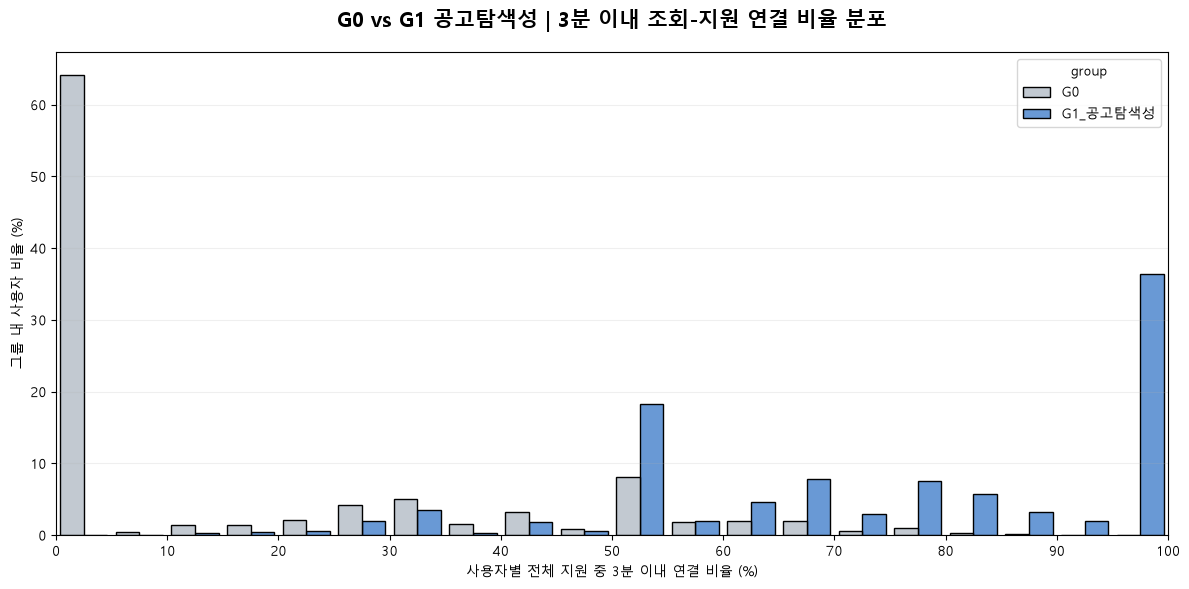

In [152]:
# 3분 이내 연결 비율을 백분율로 변환
plot_df = repeat_compare.copy()
plot_df['match_3min_pct'] = plot_df['match_3min_ratio'] * 100

plt.figure(figsize=(12, 6))

sns.histplot(
    data=plot_df,
    x='match_3min_pct',
    hue='group',
    bins=np.linspace(0, 100, 21),
    stat='percent',
    common_norm=False,
    multiple='dodge',
    shrink=0.85,
    palette={
        'G0': '#AEB8C2',
        'G1_공고탐색성': '#3777C8'
    }
)

plt.title(
    'G0 vs G1 공고탐색성 | 3분 이내 조회-지원 연결 비율 분포',
    fontsize=15,
    fontweight='bold',
    pad=18
)
plt.xlabel('사용자별 전체 지원 중 3분 이내 연결 비율 (%)')
plt.ylabel('그룹 내 사용자 비율 (%)')
plt.xticks(np.arange(0, 101, 10))
plt.xlim(0, 100)
plt.grid(axis='y', alpha=0.2)
plt.tight_layout()
plt.show()

In [153]:
# G1 공고탐색성 사용자만 추출
g1_repeat_check = g1_view_repeat.copy()

# 지원 건수 구간 생성
g1_repeat_check['application_group'] = pd.cut(
    g1_repeat_check['total_applications'],
    bins=[0, 1, 2, 4, 9, float('inf')],
    labels=['1건', '2건', '3~4건', '5~9건', '10건 이상']
)

# 지원 건수별 연결 비율 비교
g1_repeat_summary = (
    g1_repeat_check.groupby(
        'application_group', observed=True
    )
    .agg(
        users=('user_uuid', 'nunique'),
        median_3min_ratio=('match_3min_ratio', 'median'),
        mean_3min_ratio=('match_3min_ratio', 'mean'),
        median_30min_ratio=('match_30min_ratio', 'median')
    )
)

g1_repeat_summary['user_ratio'] = (
    g1_repeat_summary['users']
    / len(g1_repeat_check) * 100
)

display(g1_repeat_summary.round(3))

,users,median_3min_ratio,mean_3min_ratio,median_30min_ratio,user_ratio
application_group,,,,,
1건,481,1.000,1.000,1.000,22.916
2건,398,0.500,0.672,1.000,18.961
3~4건,428,0.667,0.655,0.750,20.391
5~9건,410,0.667,0.666,0.833,19.533
10건 이상,382,0.727,0.709,0.900,18.199


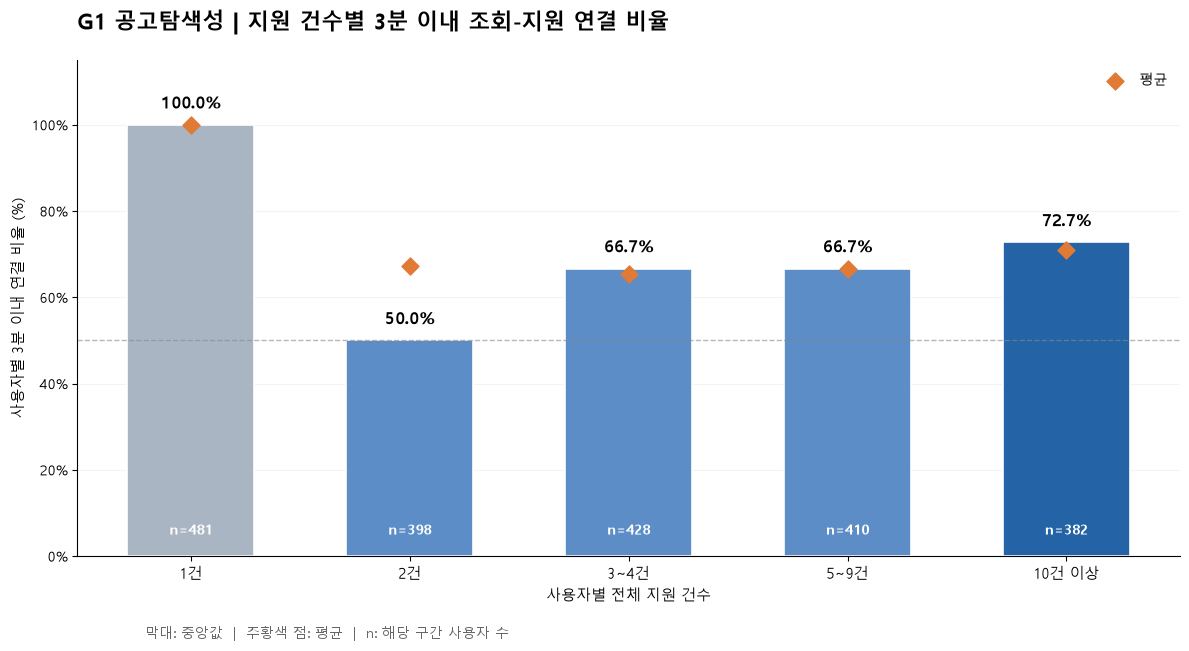

In [154]:
plot_df = g1_repeat_summary.reset_index().copy()

plot_df['median_pct'] = plot_df['median_3min_ratio'] * 100
plot_df['mean_pct'] = plot_df['mean_3min_ratio'] * 100

x = np.arange(len(plot_df))

fig, ax = plt.subplots(figsize=(12, 6.5))

colors = ['#AAB5C3', '#5C8DC6', '#5C8DC6', '#5C8DC6', '#2463A6']

bars = ax.bar(
    x,
    plot_df['median_pct'],
    width=0.58,
    color=colors,
    edgecolor='white',
    linewidth=1.2,
    zorder=2
)

# 평균을 점으로 표시
ax.scatter(
    x,
    plot_df['mean_pct'],
    color='#E07A35',
    s=75,
    marker='D',
    zorder=4,
    label='평균'
)

# 막대 위 중앙값 및 사용자 수
for i, bar in enumerate(bars):
    median = plot_df.iloc[i]['median_pct']
    users = int(plot_df.iloc[i]['users'])

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        median + 3,
        f'{median:.1f}%',
        ha='center',
        va='bottom',
        fontsize=12,
        fontweight='bold'
    )

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        5,
        f'n={users:,}',
        ha='center',
        fontsize=10,
        color='white' if median >= 25 else '#333333',
        fontweight='bold'
    )

# 기준선
ax.axhline(
    50,
    color='#888888',
    linestyle='--',
    linewidth=1,
    alpha=0.6
)

ax.set_xticks(x)
ax.set_xticklabels(plot_df['application_group'], fontsize=11)
ax.set_ylim(0, 115)
ax.set_yticks(np.arange(0, 101, 20))
ax.set_yticklabels([f'{v}%' for v in range(0, 101, 20)])

ax.set_title(
    'G1 공고탐색성 | 지원 건수별 3분 이내 조회-지원 연결 비율',
    fontsize=16,
    fontweight='bold',
    loc='left',
    pad=22
)

ax.set_ylabel('사용자별 3분 이내 연결 비율 (%)', fontsize=11)
ax.set_xlabel('사용자별 전체 지원 건수', fontsize=11)

ax.grid(axis='y', alpha=0.15, zorder=0)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, loc='upper right')

fig.text(
    0.125, 0.01,
    '막대: 중앙값  |  주황색 점: 평균  |  n: 해당 구간 사용자 수',
    fontsize=10,
    color='#666666'
)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

- **지원 건수가 많아져도 짧은 조회-지원 간격이 유지됨.** 3~4건 및 5~9건 지원자의 3분 이내 연결 비율 중앙값은 66.7%, 10건 이상 지원자는 72.7%로 나타남.

- **일부 지원에서만 나타난 일시적 행동이 아님을 확인.** 특히 10건 이상 지원한 382명에서도 높은 연결 비율이 유지되어, 짧은 조회-지원 간격이 반복적으로 관찰됨.
- **G1 공고탐색성 신호의 설명력 강화.** 평균 3분 이내라는 기존 기준이 소수 지원 건에 의해서만 나타난 결과가 아니라, 지원 건수가 많은 사용자에게서도 확인되는 행동 특성임을 뒷받침함.

> G1 공고탐색성 사용자는 지원 건수와 관계없이 지원 직전 짧은 조회-지원 간격이 반복적으로 관찰되는 경향을 보임.

### 13-1-6. G1 행동 특성 요약 및 잠정 유형

#### 🔵 G1 | 지원 직전 탐색 후 빠른 지원형

지원 직전 공고 조회와 지원 사이의 시간 간격이 짧게 나타나는 행동이 대표적인 단일 신호 사용자 집단

**핵심 근거**

- G1의 **71.4%** 가 공고탐색성 신호 보유
- 공고탐색성 사용자의 3분 이내 조회-지원 연결 비율 중앙값 75%
- 10건 이상 지원자에서도 **중앙값 72.7%**로 짧은 시간 간격이 반복적으로 관찰됨

**핵심 인사이트**

G1은 지원량보다 지원 직전 짧은 조회-지원 간격이 대표적인 특징이며, 공고탐색성 사용자 중 10건 이상 지원한 집단에서도 이러한 행동이 반복적으로 관찰됨.

**개선 방향**

빠른 지원 흐름을 유지하면서도 직무 적합성과 필수 자격요건을 쉽게 확인할 수 있도록 지원 직전 핵심 공고 정보 제공 기능을 강화한다.

## 13-2. G0 vs A | 지원행동 복합형 (151명)

**정의:** 대량성·집중성·다양성 중 **2개 이상**, 공고탐색성 0, 북마크탐색성 0.  
**비교 질문:** 지원 규모가 크더라도 공고 조회와 북마크 행동이 비례해 증가하는가?

> 공고탐색성 0은 **공고 조회가 없었다**는 뜻이 아니라, 정의된 '짧은 조회-지원 간격' 신호가 검출되지 않았다는 의미다.

### 13-2-0. G0·A 사용자 추출

In [155]:
ga_users = get_group_users('A')
print(ga_users['final_segment'].value_counts())

final_segment
G0_신호없음      6484
A_지원행동복합형     151
Name: count, dtype: int64


### 13-2-1. 지원 행동 비교

,users,mean_applications,median_applications,p75_applications,p90_applications,median_active_days,median_activity_span,median_applications_per_day
final_segment,,,,,,,,
G0_신호없음,6484,4.40,2.0,5.0,11.0,1.0,1.08,1.00
A_지원행동복합형,151,93.36,38.0,69.0,115.0,7.0,117.02,5.67


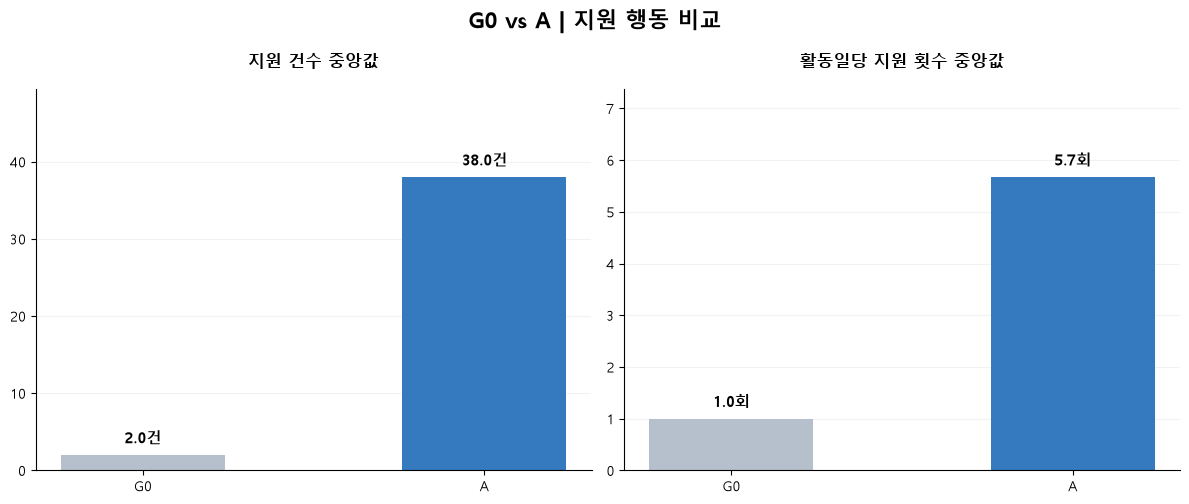

In [156]:
ga_apply_features = get_group_users('A')
ga_apply_summary = run_behavior('A', 'application')

In [ ]:
import pandas as pd
from scipy import stats

g0_apps = user_behavior[user_behavior['final_segment'] == 'G0_신호없음']['total_applications']
a_apps = user_behavior[user_behavior['final_segment'] == 'A_지원행동복합형']['total_applications']

t_stat, p_value = stats.ttest_ind(g0_apps, a_apps, equal_var=False)

result_df = pd.DataFrame({
    '비교 그룹': ['G0 (신호 없음) vs A (지원행동복합형)'],
    '비교 지표': ['총 지원 횟수'],
    '검정 방법': ["Welch's t-test"],
    't-통계량': [f"{t_stat:.4f}"],
    'p-value': [f"{p_value:.5e}"],
    '유의성 판정': ['유의함 (p < 0.05)' if p_value < 0.05 else '유의하지 않음']
})

display(result_df)

,비교 그룹,비교 지표,검정 방법,t-통계량,p-value,유의성 판정
0,G0 (신호 없음) vs A (지원행동복합형),총 지원 횟수,Welch's t-test,-2.3957,1.78209e-02,유의함 (p < 0.05)


A(지원행동복합형) 그룹이 G0(신호 없음) 그룹에 비해 통계적으로 유의미하게 더 많은 지원 행동을 보인다는 점이 객관적으로 입증되었습니다

#### 결과 해석 | A의 지원 행동

- **지원 건수 중앙값 38건**으로 G0(2건)보다 높다. 지원 건수 **평균 93.36건**은 일부 고지원 사용자의 영향을 받을 수 있으므로 중앙값을 우선 해석한다.
- **지원 활동일수 중앙값 7일**, **활동일당 지원 중앙값 5.67건**으로 G0(각 1일, 1건)와 차이를 보인다.
- **지원 활동기간 중앙값 117.02일**은 첫 지원일부터 마지막 지원일까지의 기간이며, 매일 활동했다는 뜻이 아니다.

**핵심:** A는 지원행동 신호가 복합적으로 나타나고 지원 규모가 큰 집단이다. 다만 높은 지원량은 분류에 사용한 대량성 신호와 연관되어 있으므로 독립적인 검증으로 해석하지 않는다.

### 13-2-2. 공고탐색 행동 비교

,users,mean_views,median_views,p75_views,p90_views,median_views_per_application,mean_views_per_application,users_with_views
final_segment,,,,,,,,
G0_신호없음,6484,82.62,34.0,92.0,204.0,12.00,27.35,6343
A_지원행동복합형,151,213.38,115.0,280.5,538.0,3.29,4.31,150


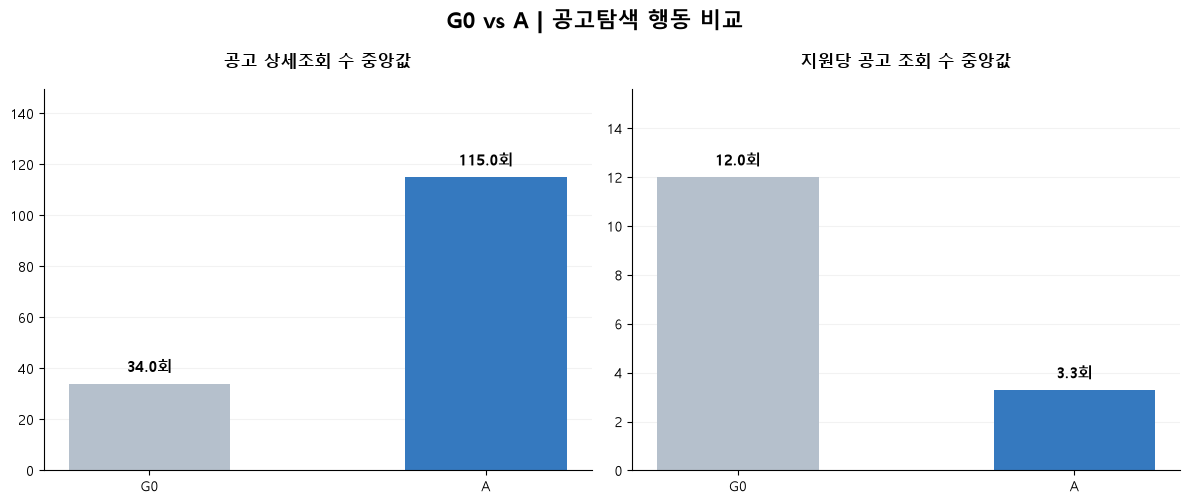

In [157]:
ga_view_features = get_group_users('A')
ga_view_summary = run_behavior('A', 'view')

In [ ]:
import pandas as pd
from scipy import stats

g0_views = user_behavior[user_behavior['final_segment'] == 'G0_신호없음']['job_view_count']
a_views = user_behavior[user_behavior['final_segment'] == 'A_지원행동복합형']['job_view_count']

t_stat, p_value = stats.ttest_ind(g0_views, a_views, equal_var=False)

result_df = pd.DataFrame({
    '비교 그룹': ['G0 (신호 없음) vs A (지원행동복합형)'],
    '비교 지표': ['공고 상세조회 횟수'],
    '검정 방법': ["Welch's t-test"],
    't-통계량': [f"{t_stat:.4f}"],
    'p-value': [f"{p_value:.5e}"],
    '유의성 판정': ['유의함 (p < 0.05)' if p_value < 0.05 else '유의하지 않음']
})

display(result_df)

,비교 그룹,비교 지표,검정 방법,t-통계량,p-value,유의성 판정
0,G0 (신호 없음) vs A (지원행동복합형),공고 상세조회 횟수,Welch's t-test,-6.4545,1.36417e-09,유의함 (p < 0.05)


, A(지원행동복합형) 그룹이 G0(신호 없음) 그룹에 비해 통계적으로 매우 유의미하게 더 많은 공고를 탐색한다는 점이 객관적으로 입증되었습니다.

#### 결과 해석 | A의 공고탐색 행동

- **공고 상세조회 수 중앙값:** A **115회**, G0 **34회** → 절대 조회량은 A가 더 많다.
- **사용자별 지원당 조회 수 중앙값:** A **3.29회**, G0 **12.00회** → 지원 규모 대비 조회 행동의 비중은 A가 낮다.

**핵심:** '조회 자체가 적다'가 아니라 **'지원량에 비해 조회량 증가 폭이 작다'**가 정확한 해석이다. 조회한 공고와 실제 지원 공고의 일치 여부는 확인할 수 없다.

### 13-2-3. 북마크 행동 비교

,users,mean_bookmarks,median_bookmarks,p75_bookmarks,p90_bookmarks,median_bookmarks_per_application,mean_bookmarks_per_application,bookmark_users,median_add,median_cancel,median_actions,bookmark_user_ratio
final_segment,,,,,,,,,,,,
G0_신호없음,6484,4.71,1.0,5.0,14.0,0.18,1.76,3444,0.0,0.0,0.0,53.12
A_지원행동복합형,151,8.16,1.0,6.5,21.0,0.01,0.23,78,1.0,0.0,1.0,51.66


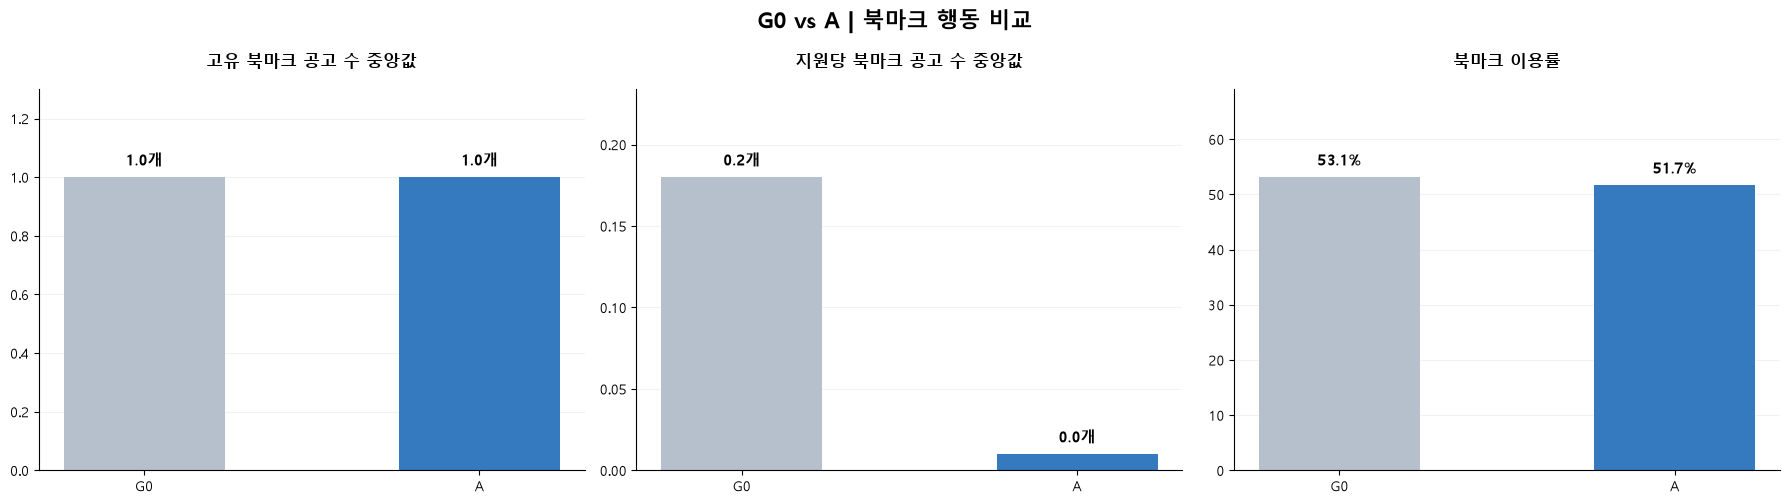

In [158]:
ga_bookmark_features = get_group_users('A')
ga_bookmark_summary = run_behavior('A', 'bookmark')

#### 결과 해석 | A의 북마크 행동

- **고유 북마크 공고 수 중앙값:** A **1개**, G0 **1개**.
- **지원당 북마크 수 중앙값:** A **0.01개**, G0 **0.18개**.
- **북마크 이용률:** A **51.66%**, G0 **53.12%**로 유사하다.

**핵심:** 북마크를 전혀 사용하지 않는 집단이 아니다. 다만 **지원량 대비 저장 행동 비중은 낮게 나타난다.** 북마크탐색성 점수 0과 북마크 이용 여부를 혼동하지 않는다.

### 13-2-4. A 복합 신호 구성 분석

#### 1) A 사용자별 행동 신호 추출

In [159]:
# A 집단 추출
a_signal = user_master_final[
    user_master_final['final_segment'] == 'A_지원행동복합형'
].copy()

score_cols = [
    'volume_score',
    'concentration_score',
    'diversity_score',
    'view_score',
    'bookmark_score'
]

signal_names = {
    'volume_score': '대량성',
    'concentration_score': '집중성',
    'diversity_score': '다양성',
    'view_score': '공고탐색성',
    'bookmark_score': '북마크탐색성'
}

print('A 사용자 수:', len(a_signal))
display(a_signal[score_cols].sum().rename(index=signal_names))

A 사용자 수: 151


대량성       143
집중성        80
다양성       105
공고탐색성       0
북마크탐색성      0
dtype: int64

#### 2) A 사용자 주요 신호 조합 확인

In [160]:
# 사용자별 활성화된 신호 조합
a_signal['signal_combination'] = a_signal[score_cols].apply(
    lambda row: ' + '.join(
        signal_names[col]
        for col in score_cols
        if row[col] == 1
    ),
    axis=1
)

a_combination_summary = (
    a_signal['signal_combination']
    .value_counts()
    .rename_axis('signal_combination')
    .reset_index(name='users')
)

a_combination_summary['ratio'] = (
    a_combination_summary['users'] / len(a_signal) * 100
).round(1)

display(a_combination_summary)

,signal_combination,users,ratio
0,대량성 + 다양성,71,47.0
1,대량성 + 집중성,46,30.5
2,대량성 + 집중성 + 다양성,26,17.2
3,집중성 + 다양성,8,5.3


#### 3) 시각화

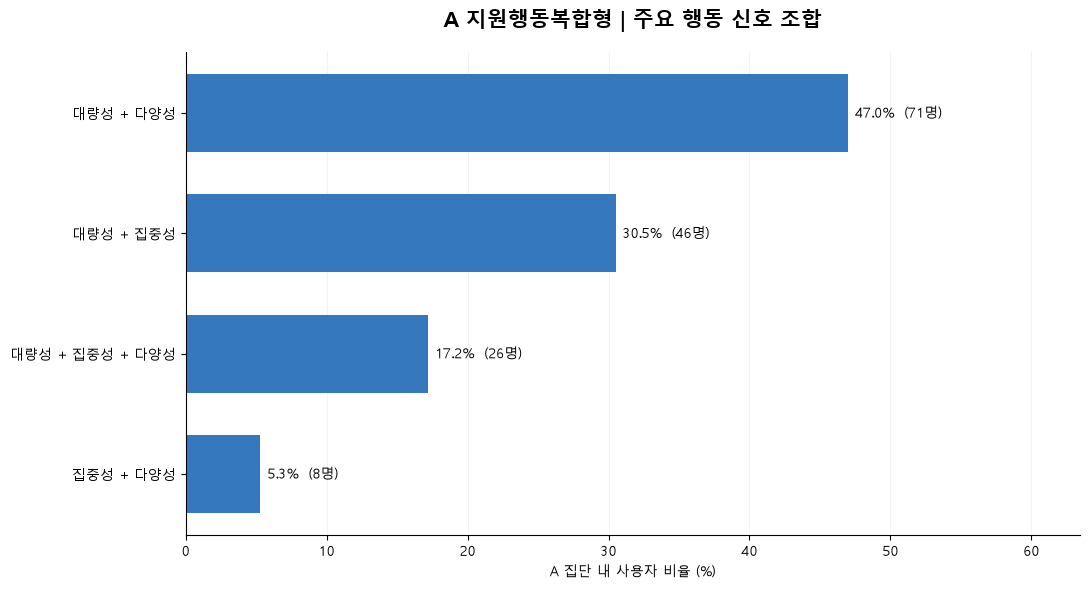

In [161]:
plot_df = a_combination_summary.head(10).iloc[::-1]

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    plot_df['signal_combination'],
    plot_df['ratio'],
    color='#3678BE',
    height=0.65
)

for bar, users, ratio in zip(
    bars,
    plot_df['users'],
    plot_df['ratio']
):
    ax.text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f'{ratio:.1f}%  ({users}명)',
        va='center',
        fontsize=10
    )

ax.set_xlim(0, max(plot_df['ratio']) * 1.35)
ax.set_xlabel('A 집단 내 사용자 비율 (%)')
ax.set_title(
    'A 지원행동복합형 | 주요 행동 신호 조합',
    fontsize=15,
    fontweight='bold',
    pad=18
)

ax.grid(axis='x', alpha=0.15)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

#### 결과 해석 | A의 지원 신호 조합

A 151명의 주요 조합은 **대량성+다양성 71명(47.0%)**, **대량성+집중성 46명(30.5%)**, **대량성+집중성+다양성 26명(17.2%)**, **집중성+다양성 8명(5.3%)**이다.

**핵심:** A는 하나의 지원 방식만 가진 집단이 아니라, **지원 규모·연속지원·직무 확장 신호가 두 개 이상 중첩된 집단**이다.

### 13-2-5. A | 다수 공고 적극 지원형

**유형 정의:** 지원행동 신호가 2개 이상 결합된 사용자 집단. **지원 건수 중앙값 38건**, **공고 조회 중앙값 115회**, **지원당 조회 중앙값 3.29회**.

**핵심 인사이트:** 공고 조회의 절대량은 많지만, 지원량 대비 조회·북마크 행동의 비중은 G0보다 낮다. 다양한 직무에 지원하거나 짧은 시간에 연속지원하는 패턴이 함께 나타난다.

**개선 방향(가설):** 다수 지원 이력 관리, 유사 공고 자격요건 비교, 직무 적합성 확인을 돕는 기능.

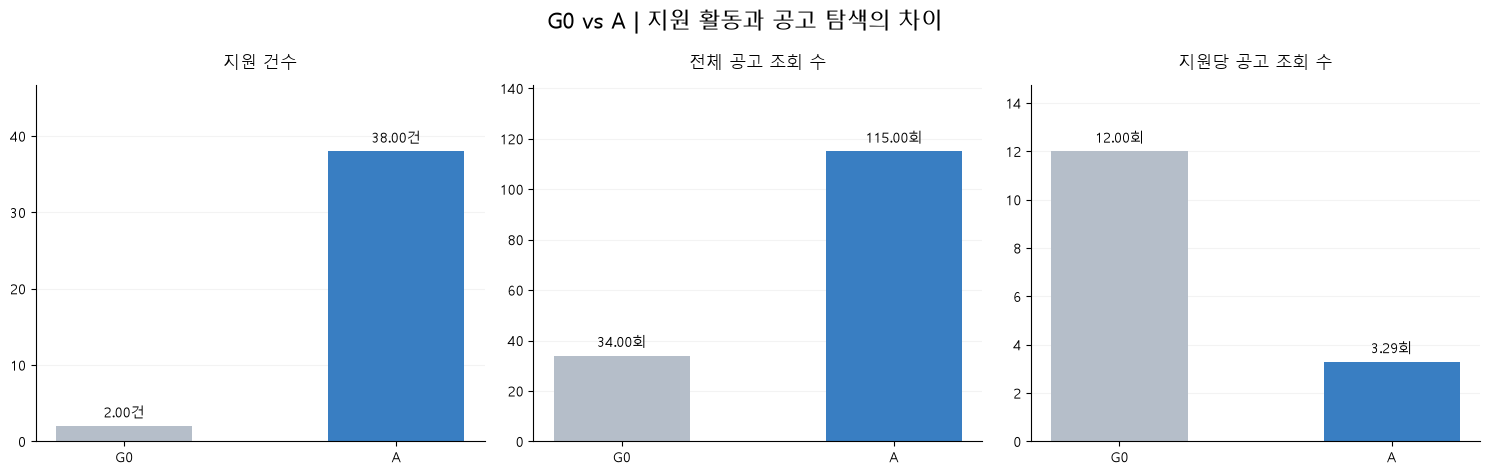

In [162]:
# 기존 하드코딩 차트를 새 A 세그먼트 집계값으로 대체
metrics = [
    ('median_applications', ga_apply_summary, '지원 건수', '건'),
    ('median_views', ga_view_summary, '전체 공고 조회 수', '회'),
    ('median_views_per_application', ga_view_summary, '지원당 공고 조회 수', '회')
]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, (metric, summary, title, unit) in zip(axes, metrics):
    values = summary[metric].to_numpy(dtype=float)
    bars = ax.bar(['G0', 'A'], values, color=['#B5BEC9', '#397EC2'], width=.5)
    upper = max(values.max(), 1)
    for bar, value in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width()/2, value + upper*.03,
                f'{value:,.2f}{unit}', ha='center', fontsize=10)
    ax.set_ylim(0, upper*1.23)
    ax.set_title(title, fontsize=12, pad=12)
    ax.grid(axis='y', alpha=.15)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('G0 vs A | 지원 활동과 공고 탐색의 차이', fontsize=16)
plt.tight_layout()
plt.show()

In [178]:
import pandas as pd
from scipy import stats

# 1. G0 그룹과 A 그룹 데이터 분리
g0_data = user_behavior[user_behavior['final_segment'] == 'G0_신호없음']
a_data = user_behavior[user_behavior['final_segment'] == 'A_지원행동복합형']

# 2. 비교할 3가지 지표 정의 (컬럼명)
metrics = {
    '지원 건수': 'total_applications',
    '전체 공고 조회 수': 'job_view_count',
    '지원당 공고 조회 수': 'views_per_application'
}

results = []

# 3. 각 지표별로 Welch's t-test 반복 수행
for label, col in metrics.items():
    g0_vals = g0_data[col]
    a_vals = a_data[col]
    
    t_stat, p_value = stats.ttest_ind(g0_vals, a_vals, equal_var=False)
    
    results.append({
        '비교 그룹': 'G0 (신호 없음) vs A (지원행동복합형)',
        '비교 지표': label,
        '검정 방법': "Welch's t-test",
        't-통계량': f"{t_stat:.4f}",
        'p-value': f"{p_value:.5e}",
        '유의성 판정': '유의함 (p < 0.05)' if p_value < 0.05 else '유의하지 않음'
    })

# 4. 통합 결과 표 출력
result_df = pd.DataFrame(results)
display(result_df)

,비교 그룹,비교 지표,검정 방법,t-통계량,p-value,유의성 판정
0,G0 (신호 없음) vs A (지원행동복합형),지원 건수,Welch's t-test,-2.3957,1.78209e-02,유의함 (p < 0.05)
1,G0 (신호 없음) vs A (지원행동복합형),전체 공고 조회 수,Welch's t-test,-6.4545,1.36417e-09,유의함 (p < 0.05)
2,G0 (신호 없음) vs A (지원행동복합형),지원당 공고 조회 수,Welch's t-test,25.7250,1.66332e-133,유의함 (p < 0.05)


지원 건수 ($t = -2.3957, p \approx 0.0178$): 유의수준 0.05 미만으로, G0 그룹에 비해 A 그룹의 지원 건수가 통계적으로 유의미하게 더 많습니다.

전체 공고 조회 수 ($t = -6.4545, p \approx 1.36 \times 10^{-9}$): 두 집단 간의 공고 상세조회 횟수 차이가 매우 뚜렷하며, A 그룹이 지원 전 탐색 활동을 훨씬 더 활발하게 수행함을 보여줍니다. 

지원당 공고 조회 수 ($t = 25.7250, p \approx 1.66 \times 10^{-133}$): $p$값이 0에 수렴할 정도로 압도적인 차이를 보이며, 지원 행동 대비 탐색 효율성 및 패턴에서 두 그룹이 극명하게 구분되는 독립적인 집단임이 입증되었습니다.

## 13-3. G0 vs B | 공고탐색 결합형 (492명)

**정의:** 지원행동 신호 **정확히 1개** + 공고탐색성 1 + 북마크탐색성 0.  
**비교 질문:** 공고 조회 직후 지원하는 신호가 다른 지원행동 신호 1개와 결합된 사용자는 어떤 지원·탐색 특성을 보이는가?

> 공고탐색성은 동일 사용자의 **직전 공고 상세조회와 지원 시점의 시간 간격**을 활용한다. 조회한 공고가 실제 지원한 공고와 동일하다는 의미는 아니다.

### 13-3-1. G0 vs B | 지원 행동 비교

,users,mean_applications,median_applications,p75_applications,p90_applications,median_active_days,median_activity_span,median_applications_per_day
final_segment,,,,,,,,
G0_신호없음,6484,4.40,2.0,5.0,11.0,1.0,1.08,1.0
B_공고탐색결합형,492,19.76,10.0,21.0,41.9,4.0,33.73,2.5


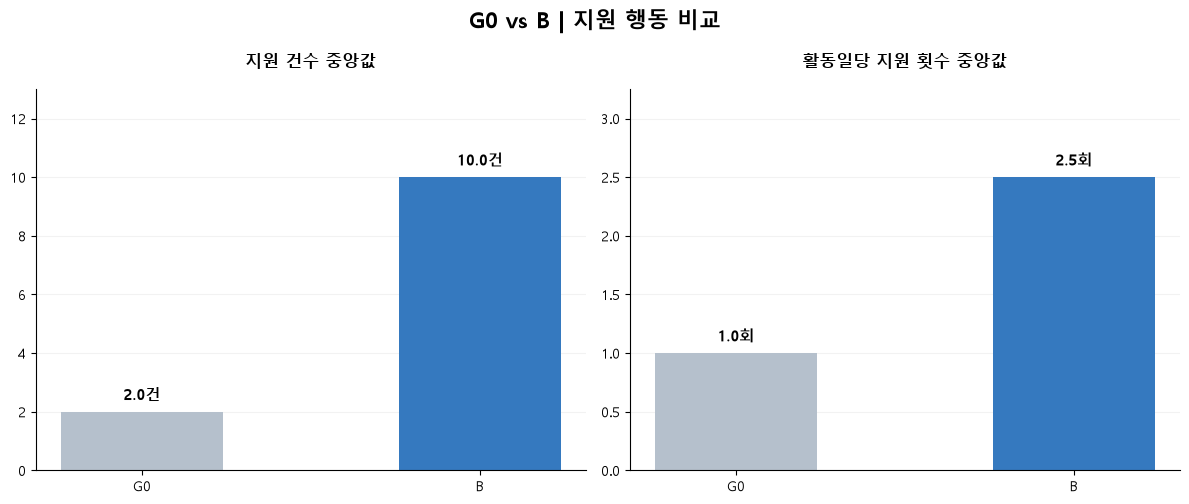

### 13-3-2. G0 vs B | 공고탐색 행동 비교

,users,mean_views,median_views,p75_views,p90_views,median_views_per_application,mean_views_per_application,users_with_views
final_segment,,,,,,,,
G0_신호없음,6484,82.62,34.0,92.00,204.0,12.00,27.35,6343
B_공고탐색결합형,492,134.74,66.0,163.25,315.0,5.63,8.41,492


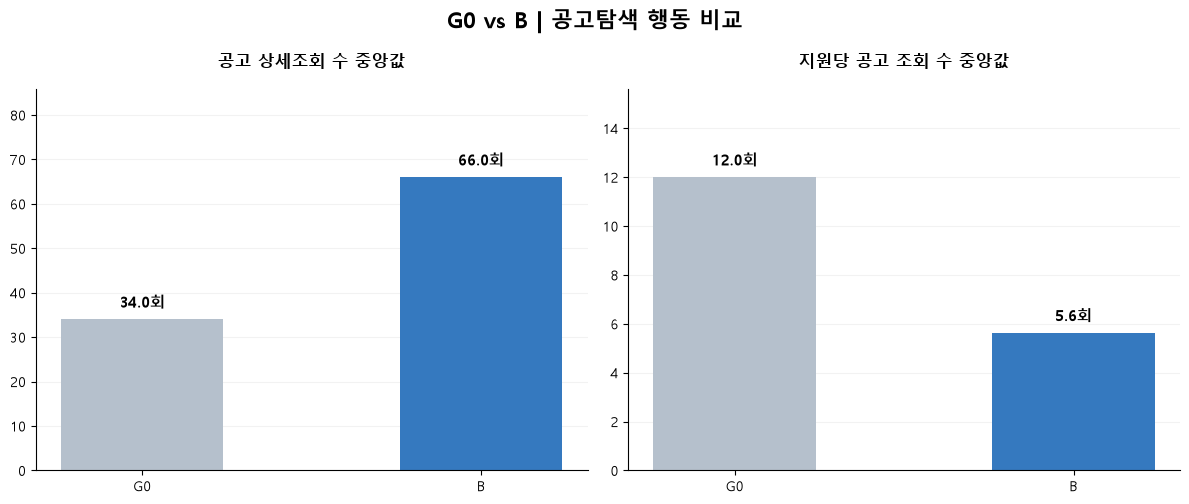

### 13-3-3. G0 vs B | 북마크 행동 비교

,users,mean_bookmarks,median_bookmarks,p75_bookmarks,p90_bookmarks,median_bookmarks_per_application,mean_bookmarks_per_application,bookmark_users,median_add,median_cancel,median_actions,bookmark_user_ratio
final_segment,,,,,,,,,,,,
G0_신호없음,6484,4.71,1.0,5.0,14.0,0.18,1.76,3444,0.0,0.0,0.0,53.12
B_공고탐색결합형,492,7.09,1.0,8.0,21.0,0.10,0.70,292,1.0,0.0,2.0,59.35


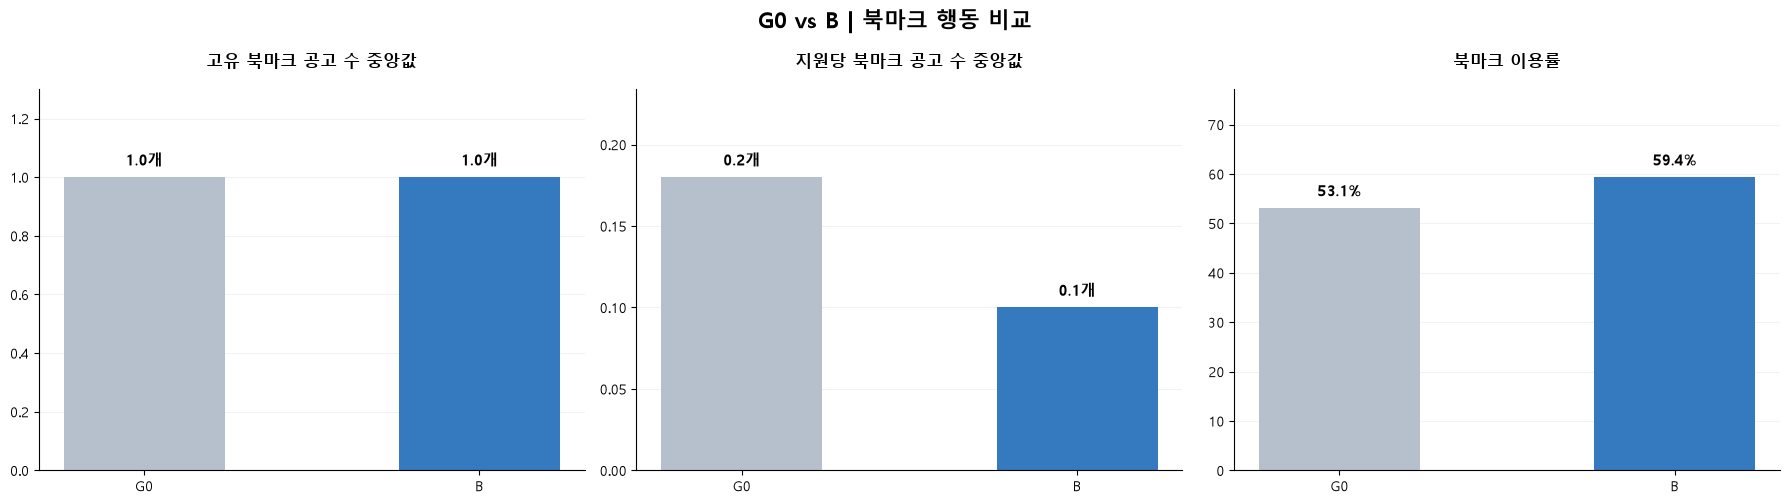

In [163]:
from IPython.display import display, Markdown

# 13-3-1. 지원 행동 비교
display(Markdown('### 13-3-1. G0 vs B | 지원 행동 비교'))
gb_apply_summary = run_behavior('B', 'application')

# 13-3-2. 공고탐색 행동 비교
display(Markdown('### 13-3-2. G0 vs B | 공고탐색 행동 비교'))
gb_view_summary = run_behavior('B', 'view')

# 13-3-3. 북마크 행동 비교
display(Markdown('### 13-3-3. G0 vs B | 북마크 행동 비교'))
gb_bookmark_summary = run_behavior('B', 'bookmark')

In [181]:
import pandas as pd
from scipy import stats

# 1. G0 그룹과 'B_공고탐색결합형' 그룹 데이터 분리
target_segment = 'B_공고탐색결합형'

g0_data = user_behavior[user_behavior['final_segment'] == 'G0_신호없음']
b_data = user_behavior[user_behavior['final_segment'] == target_segment]

# 2. 비교할 3가지 지표 정의 (지원 건수, 공고 상세조회 횟수, 지원당 공고 조회 수)
metrics = {
    '지원 건수': 'total_applications',
    '공고 상세조회 횟수': 'job_view_count',
    '지원당 공고 조회 수': 'views_per_application'
}

results = []

# 3. 각 지표별로 Welch's t-test 반복 수행
for label, col in metrics.items():
    g0_vals = g0_data[col].dropna()
    b_vals = b_data[col].dropna()
    
    if len(g0_vals) > 1 and len(b_vals) > 1:
        t_stat, p_value = stats.ttest_ind(g0_vals, b_vals, equal_var=False)
        t_str = f"{t_stat:.4f}"
        p_str = f"{p_value:.5e}"
        judgement = '유의함 (p < 0.05)' if p_value < 0.05 else '유의하지 않음'
    else:
        t_str = "데이터 부족"
        p_str = "데이터 부족"
        judgement = '판단 불가'

    results.append({
        '비교 그룹': f'G0 (신호 없음) vs B ({target_segment})',
        '비교 지표': label,
        '검정 방법': "Welch's t-test",
        't-통계량': t_str,
        'p-value': p_str,
        '유의성 판정': judgement
    })

# 4. 최종 결과 표 출력
result_df = pd.DataFrame(results)
display(result_df)

,비교 그룹,비교 지표,검정 방법,t-통계량,p-value,유의성 판정
0,G0 (신호 없음) vs B (B_공고탐색결합형),지원 건수,Welch's t-test,-9.9696,1.88460e-21,유의함 (p < 0.05)
1,G0 (신호 없음) vs B (B_공고탐색결합형),공고 상세조회 횟수,Welch's t-test,-5.6836,2.16647e-08,유의함 (p < 0.05)
2,G0 (신호 없음) vs B (B_공고탐색결합형),지원당 공고 조회 수,Welch's t-test,19.5577,1.84589e-81,유의함 (p < 0.05)


지원 건수 ($t = -9.9696, p \approx 1.88 \times 10^{-21}$): 유의수준 0.05 미만이며 $p$값이 매우 낮아, G0 그룹에 비해 B 그룹의 지원 건수가 통계적으로 압도적으로 더 많습니다.

전체 공고 조회 수 ($t = -5.6836, p \approx 2.17 \times 10^{-8}$): 두 집단 간의 공고 상세조회 횟수 차이가 뚜렷하며, B 그룹이 지원 전 탐색 활동을 훨씬 더 활발하게 수행함을 보여줍니다.

지원당 공고 조회 수 ($t = 19.5577, p \approx 1.85 \times 10^{-81}$): $p$값이 0에 수렴할 정도로 극단적인 차이를 보여, 두 그룹 간의 탐색 및 지원 패턴이 명확히 구분되는 독립적인 집단임이 입증되었습니다.

### 13-3-4. B의 신호 구성 | 공고탐색성 + 지원행동 신호 1개

B **492명 전원**이 공고탐색성 신호를 보유한다. 지원행동 신호의 구성은 **다양성 281명(57.1%)**, **집중성 114명(23.2%)**, **대량성 97명(19.7%)**이다.

**핵심:** B는 '여러 직무를 지원하는 사용자'만을 뜻하지 않는다. 세 가지 지원행동 신호 중 **하나**와 짧은 조회-지원 간격 신호가 결합된 유형이다.

In [164]:
from IPython.display import display, Markdown

# B 사용자 추출
b_users = user_master_final[
    user_master_final['final_segment'] == 'B_공고탐색결합형'
].copy()

score_cols = [
    'volume_score',
    'concentration_score',
    'diversity_score',
    'view_score',
    'bookmark_score'
]

score_names = {
    'volume_score': '대량성',
    'concentration_score': '집중성',
    'diversity_score': '다양성',
    'view_score': '공고탐색성',
    'bookmark_score': '북마크탐색성'
}

# 사용자별 활성화된 신호 조합
b_users['signal_combination'] = b_users[score_cols].apply(
    lambda row: ' + '.join(
        score_names[col] for col in score_cols if row[col] == 1
    ),
    axis=1
)

# 조합별 사용자 수와 비율
b_signal_summary = (
    b_users['signal_combination']
    .value_counts()
    .rename_axis('신호 조합')
    .reset_index(name='사용자 수')
)

b_signal_summary['비율(%)'] = (
    b_signal_summary['사용자 수'] / len(b_users) * 100
).round(1)

display(Markdown('#### B | 복합 행동 신호 조합 요약표'))
display(b_signal_summary)

# 개별 신호 보유 비율
b_score_summary = pd.DataFrame({
    '신호': [score_names[col] for col in score_cols],
    '사용자 수': [int(b_users[col].sum()) for col in score_cols]
})

b_score_summary['비율(%)'] = (
    b_score_summary['사용자 수'] / len(b_users) * 100
).round(1)

display(Markdown('#### B | 개별 행동 신호 보유 현황'))
display(b_score_summary)

#### B | 복합 행동 신호 조합 요약표

,신호 조합,사용자 수,비율(%)
0,다양성 + 공고탐색성,281,57.1
1,집중성 + 공고탐색성,114,23.2
2,대량성 + 공고탐색성,97,19.7


#### B | 개별 행동 신호 보유 현황

,신호,사용자 수,비율(%)
0,대량성,97,19.7
1,집중성,114,23.2
2,다양성,281,57.1
3,공고탐색성,492,100.0
4,북마크탐색성,0,0.0


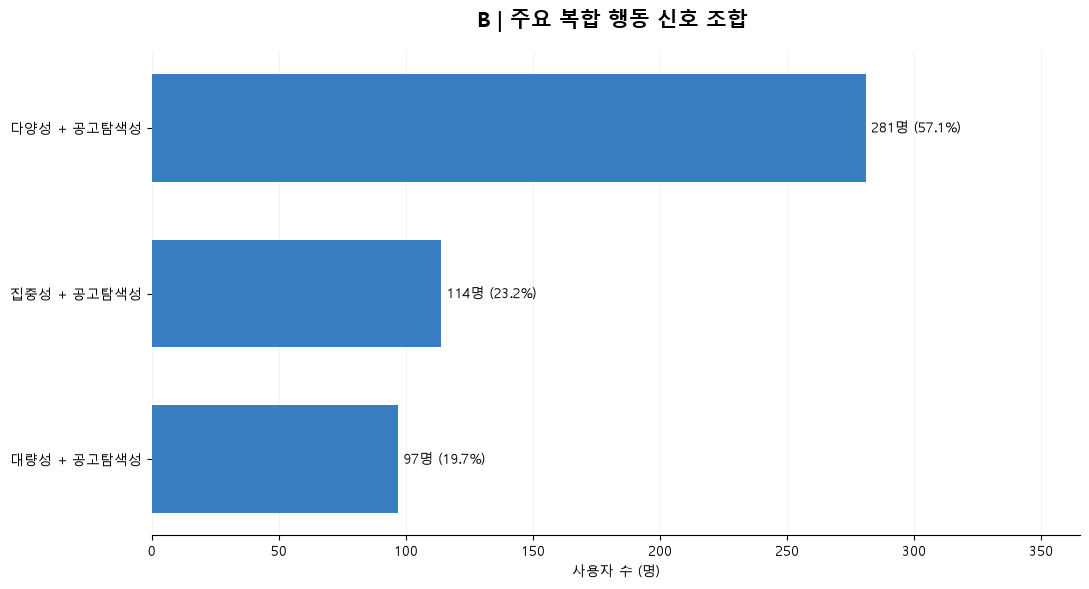

In [165]:
plot_df = b_signal_summary.iloc[::-1]

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    plot_df['신호 조합'],
    plot_df['사용자 수'],
    color='#397EC2',
    height=0.65
)

for bar, count, ratio in zip(
    bars,
    plot_df['사용자 수'],
    plot_df['비율(%)']
):
    ax.text(
        bar.get_width() + 2,
        bar.get_y() + bar.get_height() / 2,
        f'{count}명 ({ratio:.1f}%)',
        va='center',
        fontsize=10
    )

ax.set_title(
    'B | 주요 복합 행동 신호 조합 ',
    fontsize=15,
    fontweight='bold',
    pad=18
)

ax.set_xlabel('사용자 수 (명)')
ax.set_xlim(0, max(plot_df['사용자 수']) * 1.3)
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.grid(axis='x', alpha=0.15)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

## 13-4. G0 vs C | 고복합 행동형 (171명)

**정의:** 지원행동 신호 **2개 이상** + 공고탐색성 1 + 북마크탐색성 0.  
**비교 질문:** A와 마찬가지로 지원행동이 복합적이면서, 공고탐색성 신호까지 결합된 C는 실제 지원·조회 행동에서 어떤 공통점과 차이를 보이는가?

> **주의:** C는 **북마크탐색 결합형이 아니다.** 북마크탐색성 신호를 포함하는 48명은 기타 복합형으로 별도 분류했다.

### 13-4-1. G0 vs C | 지원 행동 비교

,users,mean_applications,median_applications,p75_applications,p90_applications,median_active_days,median_activity_span,median_applications_per_day
final_segment,,,,,,,,
G0_신호없음,6484,4.40,2.0,5.0,11.0,1.0,1.08,1.0
C_고복합행동형,171,72.11,37.0,71.0,129.0,5.0,74.55,6.0


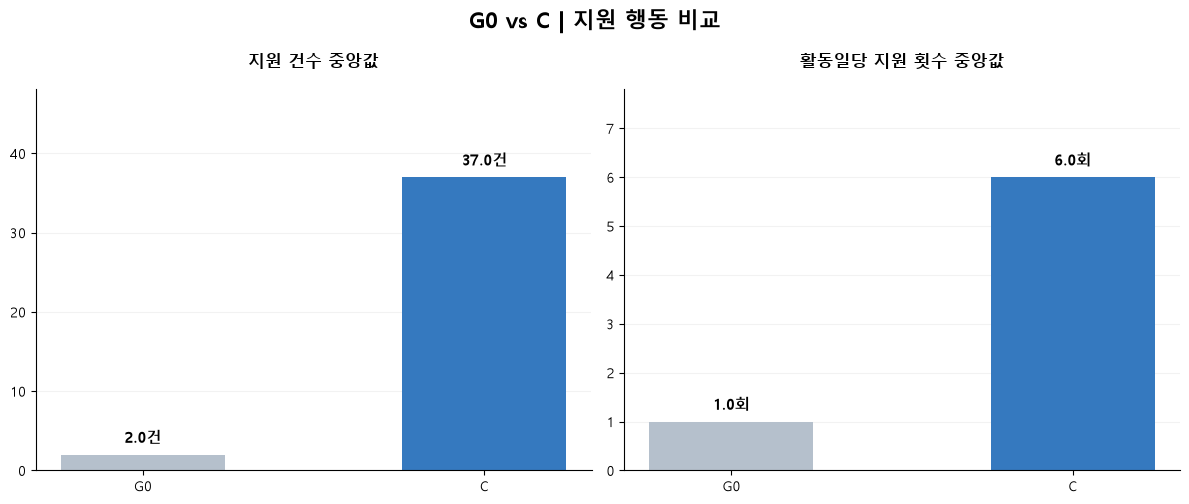

### 13-4-2. G0 vs C | 공고탐색 행동 비교

,users,mean_views,median_views,p75_views,p90_views,median_views_per_application,mean_views_per_application,users_with_views
final_segment,,,,,,,,
G0_신호없음,6484,82.62,34.0,92.0,204.0,12.00,27.35,6343
C_고복합행동형,171,260.32,136.0,302.5,657.0,3.31,4.21,171


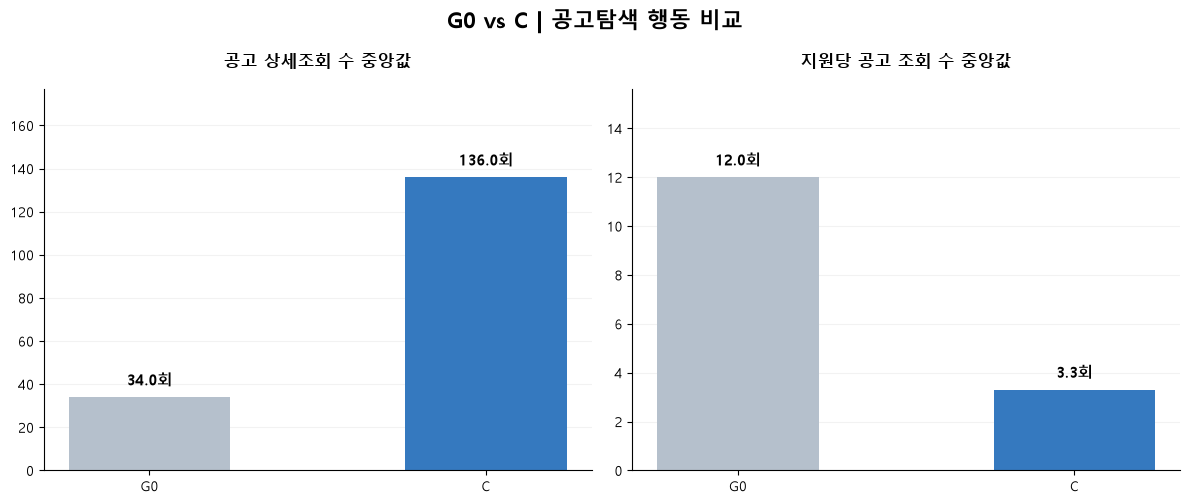

### 13-4-3. G0 vs C | 북마크 행동 비교

,users,mean_bookmarks,median_bookmarks,p75_bookmarks,p90_bookmarks,median_bookmarks_per_application,mean_bookmarks_per_application,bookmark_users,median_add,median_cancel,median_actions,bookmark_user_ratio
final_segment,,,,,,,,,,,,
G0_신호없음,6484,4.71,1.0,5.0,14.0,0.18,1.76,3444,0.0,0.0,0.0,53.12
C_고복합행동형,171,7.58,0.0,6.0,20.0,0.00,0.21,83,0.0,0.0,0.0,48.54


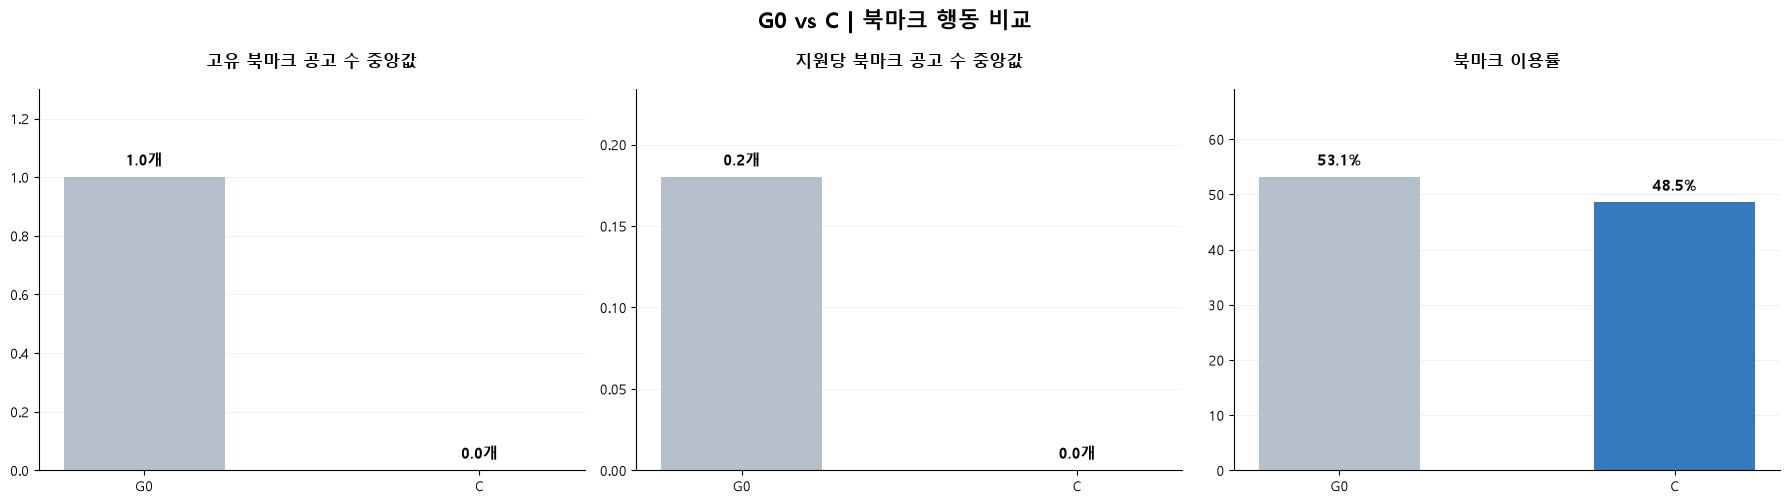

In [166]:
from IPython.display import display, Markdown

display(Markdown('### 13-4-1. G0 vs C | 지원 행동 비교'))
gc_apply_summary = run_behavior('C', 'application')

display(Markdown('### 13-4-2. G0 vs C | 공고탐색 행동 비교'))
gc_view_summary = run_behavior('C', 'view')

display(Markdown('### 13-4-3. G0 vs C | 북마크 행동 비교'))
gc_bookmark_summary = run_behavior('C', 'bookmark')

In [182]:
import pandas as pd
from scipy import stats

# 1. G0 그룹과 'C_고복합행동형' 그룹 데이터 분리
target_segment = 'C_고복합행동형'

g0_data = user_behavior[user_behavior['final_segment'] == 'G0_신호없음']
c_data = user_behavior[user_behavior['final_segment'] == target_segment]

# 2. 비교할 3가지 지표 정의 (지원 건수, 공고 상세조회 횟수, 지원당 공고 조회 수)
metrics = {
    '지원 건수': 'total_applications',
    '공고 상세조회 횟수': 'job_view_count',
    '지원당 공고 조회 수': 'views_per_application'
}

results = []

# 3. 각 지표별로 Welch's t-test 반복 수행
for label, col in metrics.items():
    g0_vals = g0_data[col].dropna()
    c_vals = c_data[col].dropna()
    
    if len(g0_vals) > 1 and len(c_vals) > 1:
        t_stat, p_value = stats.ttest_ind(g0_vals, c_vals, equal_var=False)
        t_str = f"{t_stat:.4f}"
        p_str = f"{p_value:.5e}"
        judgement = '유의함 (p < 0.05)' if p_value < 0.05 else '유의하지 않음'
    else:
        t_str = "데이터 부족"
        p_str = "데이터 부족"
        judgement = '판단 불가'

    results.append({
        '비교 그룹': f'G0 (신호 없음) vs C ({target_segment})',
        '비교 지표': label,
        '검정 방법': "Welch's t-test",
        't-통계량': t_str,
        'p-value': p_str,
        '유의성 판정': judgement
    })

# 4. 최종 결과 표 출력
result_df = pd.DataFrame(results)
display(result_df)

,비교 그룹,비교 지표,검정 방법,t-통계량,p-value,유의성 판정
0,G0 (신호 없음) vs C (C_고복합행동형),지원 건수,Welch's t-test,-7.3764,6.84537e-12,유의함 (p < 0.05)
1,G0 (신호 없음) vs C (C_고복합행동형),공고 상세조회 횟수,Welch's t-test,-6.2398,3.31694e-09,유의함 (p < 0.05)
2,G0 (신호 없음) vs C (C_고복합행동형),지원당 공고 조회 수,Welch's t-test,27.3052,4.60357e-155,유의함 (p < 0.05)


지원 건수 ($t = -7.3764, p \approx 6.85 \times 10^{-12}$): 유의수준 0.05 미만이며 $p$값이 매우 낮아, G0 그룹에 비해 C 그룹의 지원 건수가 통계적으로 유의미하게 훨씬 더 많습니다.

전체 공고 조회 수 ($t = -6.2398, p \approx 3.32 \times 10^{-9}$): 두 집단 간의 공고 상세조회 횟수 차이가 뚜렷하며, C 그룹이 지원 전 탐색 활동을 압도적으로 활발하게 수행함을 보여줍니다.

지원당 공고 조회 수 ($t = 27.3052, p \approx 4.60 \times 10^{-155}$): $p$값이 0에 수렴할 정도로 극단적인 차이를 보여, 두 그룹 간의 탐색 및 지원 패턴이 명확히 구분되는 독립적인 집단임이 입증되었습니다.

### 13-4-4. C의 신호 구성 | 지원행동 2개 이상 + 공고탐색성

C **171명 전원**은 공고탐색성 신호와 지원행동 신호 2개 이상을 함께 보유한다. 북마크탐색성 신호는 0이다.

- **대량성+집중성+공고탐색성:** 68명(39.8%)
- **대량성+다양성+공고탐색성:** 43명(25.1%)
- **대량성+집중성+다양성+공고탐색성:** 43명(25.1%)
- **집중성+다양성+공고탐색성:** 17명(9.9%)

**핵심:** C는 단순히 공고를 많이 조회하는 집단이 아니라, **복수의 지원행동 신호와 짧은 조회-지원 간격 신호가 동시에 나타나는 집단**이다.

,신호 조합,사용자 수,비율(%)
0,대량성 + 집중성 + 공고탐색성,68,39.8
1,대량성 + 다양성 + 공고탐색성,43,25.1
2,대량성 + 집중성 + 다양성 + 공고탐색성,43,25.1
3,집중성 + 다양성 + 공고탐색성,17,9.9


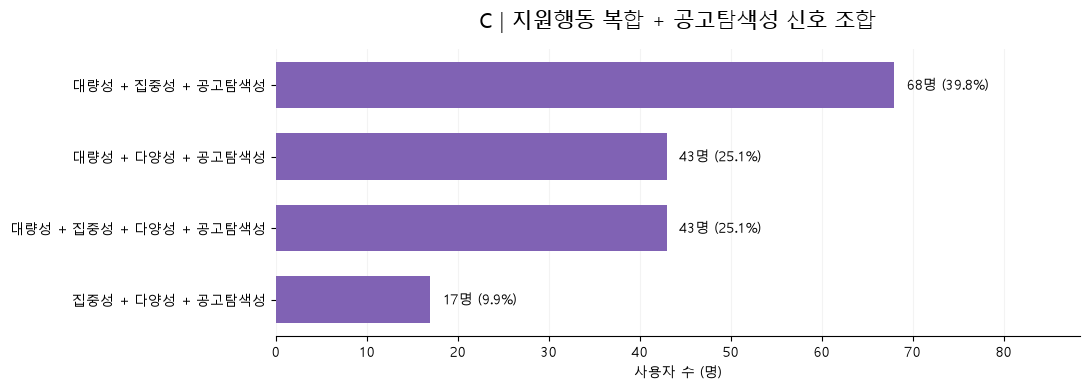

In [167]:
c_users = user_master_final.loc[user_master_final['final_segment'].eq(SEGMENTS['C'])].copy()
score_cols = ['volume_score', 'concentration_score', 'diversity_score', 'view_score', 'bookmark_score']
score_names = {'volume_score':'대량성', 'concentration_score':'집중성', 'diversity_score':'다양성', 'view_score':'공고탐색성', 'bookmark_score':'북마크탐색성'}
c_users['signal_combination'] = c_users[score_cols].apply(
    lambda row: ' + '.join(score_names[col] for col in score_cols if row[col] == 1), axis=1
)
c_signal_summary = c_users['signal_combination'].value_counts().rename_axis('신호 조합').reset_index(name='사용자 수')
c_signal_summary['비율(%)'] = (c_signal_summary['사용자 수'] / len(c_users) * 100).round(1)
display(c_signal_summary)
plot_df = c_signal_summary.iloc[::-1]
fig, ax = plt.subplots(figsize=(11, max(4, len(plot_df)*.48 + 1)))
ax.barh(plot_df['신호 조합'], plot_df['사용자 수'], color='#8062B4', height=.65)
for i, row in enumerate(plot_df.itertuples(index=False)):
    ax.text(row[1] + max(plot_df['사용자 수'])*.02, i, f'{row[1]}명 ({row[2]:.1f}%)', va='center')
ax.set_xlim(0, max(plot_df['사용자 수']) * 1.3)
ax.set_title('C | 지원행동 복합 + 공고탐색성 신호 조합', fontsize=15, pad=15)
ax.set_xlabel('사용자 수 (명)')
ax.grid(axis='x', alpha=.15)
ax.set_axisbelow(True)
ax.spines[['top','right','left']].set_visible(False)
plt.tight_layout()
plt.show()

### 13-4-5. C | 고복합 행동형 결과 해석

- **지원 건수 중앙값 37건**, **활동일수 5일**, **활동일당 지원 6.00건**으로 지원 활동 규모가 크다.
- **공고 조회 중앙값 136회**로 G0(34회)보다 높지만, **지원당 조회 중앙값은 3.31회**로 G0(12.00회)보다 낮다.
- **고유 북마크 중앙값 0개**, **지원당 북마크 중앙값 0.00개**이다. 이는 사용자 전원이 북마크를 사용하지 않았다는 의미는 아니다.

**A와의 비교:** A와 C의 지원 건수 중앙값(**38건 vs 37건**)과 지원당 조회 수(**3.29회 vs 3.31회**)는 매우 유사하다. 따라서 **'실제 지원량이 뚜렷하게 다른 유형'이라고 주장할 수 없다.** C의 차이는 공고탐색성 신호가 추가로 결합된 **행동 신호 구조**에 있으며, 독립적인 행동 차이는 추가 검증이 필요하다.

**개선 방향(가설):** 반복 지원 흐름을 방해하지 않으면서 지원 직전 공고의 필수 자격요건·근무조건을 확인하도록 돕는 기능.

## 13-5. 전체 사용자 유형 종합 비교

**비교 대상:** G0 6,484명 · G1 2,941명 · A 151명 · B 492명 · C 171명 (**10,239명**). 북마크탐색성 포함 **기타 복합형 48명**은 주요 다섯 유형 비교에서 제외하되 전체 사용자 수에서는 유지한다.

**핵심 질문:** 신호 조합으로 구분한 유형이 실제 지원량·활동일수·조회량·지원당 탐색 비중에서 어떤 공통점과 차이를 보이는가?

### 13-5-1. 전체 그룹 행동 비교 요약표

- 사용자별 지표를 먼저 계산한 뒤 그룹별 **중앙값**을 집계합니다.
- `지원당 공고 조회 수`, `지원당 북마크 수`는 각 사용자 비율의 중앙값으로, 그룹 총합의 비율과 다릅니다.
- 활동일수는 **지원 발생일수**이며, 플랫폼 전체 방문일수나 리텐션이 아닙니다.

In [168]:
from IPython.display import display, Markdown

segment_order = ['G0', 'G1', 'A', 'B', 'C']
segment_labels = {SEGMENTS[key]: key for key in segment_order}

all_group_users = user_behavior[
    user_behavior['final_segment'].isin(segment_labels)
].copy()
all_group_users['그룹'] = all_group_users['final_segment'].map(segment_labels)

all_group_summary = (
    all_group_users.groupby('그룹')
    .agg(
        사용자수=('user_uuid', 'nunique'),
        지원건수_중앙값=('total_applications', 'median'),
        활동일수_중앙값=('active_days', 'median'),
        활동기간_중앙값=('activity_span_days', 'median'),
        활동일당지원_중앙값=('applications_per_active_day', 'median'),
        공고조회_중앙값=('job_view_count', 'median'),
        지원당조회_중앙값=('views_per_application', 'median'),
        지원당북마크_중앙값=('bookmarks_per_application', 'median'),
        북마크이용률=('has_bookmark', lambda x: x.mean() * 100)
    )
    .reindex(segment_order)
    .round(2)
)

display(Markdown('#### 전체 그룹 | 사용자 행동 비교 요약표'))
display(all_group_summary)

#### 전체 그룹 | 사용자 행동 비교 요약표

,사용자수,지원건수_중앙값,활동일수_중앙값,활동기간_중앙값,활동일당지원_중앙값,공고조회_중앙값,지원당조회_중앙값,지원당북마크_중앙값,북마크이용률
그룹,,,,,,,,,
G0,6484,2.0,1.0,1.08,1.00,34.0,12.00,0.18,53.12
G1,2941,4.0,3.0,17.81,1.53,47.0,9.00,0.17,56.41
A,151,38.0,7.0,117.02,5.67,115.0,3.29,0.01,51.66
B,492,10.0,4.0,33.73,2.50,66.0,5.63,0.10,59.35
C,171,37.0,5.0,74.55,6.00,136.0,3.31,0.00,48.54


### 13-5-2. 전체 그룹 핵심 행동 지표 시각화

지원량·활동일수·조회량·지원당 조회 수를 비교합니다. 각 차트는 **개별 축**을 사용하므로 서로 다른 지표의 막대 높이를 직접 비교하지 않습니다.

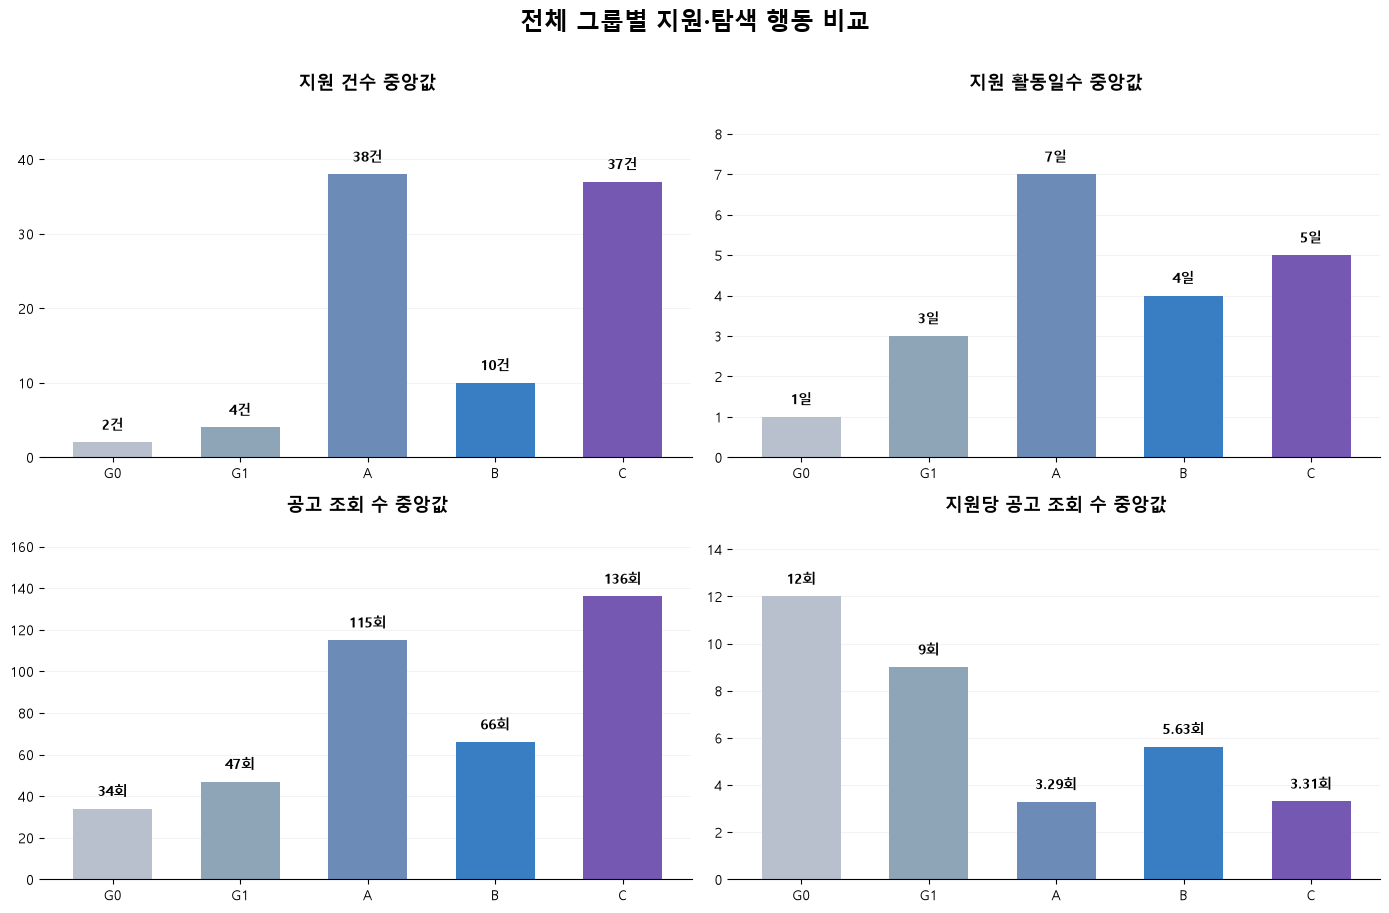

In [169]:
import matplotlib.pyplot as plt
import numpy as np

plot_metrics = [
    ('지원건수_중앙값', '지원 건수 중앙값', '건'),
    ('활동일수_중앙값', '지원 활동일수 중앙값', '일'),
    ('공고조회_중앙값', '공고 조회 수 중앙값', '회'),
    ('지원당조회_중앙값', '지원당 공고 조회 수 중앙값', '회')
]

palette = ['#B7C0CC', '#8DA5B7', '#6C8CB7', '#397EC2', '#7558B2']
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, (metric, title, unit) in zip(axes.flat, plot_metrics):
    values = all_group_summary[metric].fillna(0)
    bars = ax.bar(segment_order, values, color=palette, width=0.62)
    top = max(values.max(), 1)
    ax.set_ylim(0, top * 1.24)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=12)
    ax.grid(axis='y', alpha=0.15)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right', 'left']].set_visible(False)

    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + top * 0.035,
            f'{value:g}{unit}',
            ha='center', va='bottom', fontsize=10, fontweight='bold'
        )

fig.suptitle('전체 그룹별 지원·탐색 행동 비교', fontsize=17, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

In [183]:
import pandas as pd
import scipy.stats as stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# 비교할 3가지 지표 정의 (컬럼명)
metrics = {
    '지원 건수': 'total_applications',
    '공고 조회 수': 'job_view_count',
    '지원당 공고 조회 수': 'views_per_application'
}

# 1. 일원 배치 분산분석 (One-way ANOVA) 결과 출력
anova_results = []
for label, col in metrics.items():
    groups = [group_data[col].dropna() for name, group_data in user_behavior.groupby('final_segment')]
    f_stat, p_value = stats.f_oneway(*groups)
    
    anova_results.append({
        '비교 지표': label,
        '검정 방법': 'One-way ANOVA',
        'F-통계량': f"{f_stat:.4f}",
        'p-value': f"{p_value:.5e}",
        '유의성 판정': '유의함 (p < 0.05)' if p_value < 0.05 else '유의하지 않음'
    })

print("=== [1] 3개 그룹 이상 분산분석(ANOVA) 결과 ===")
anova_df = pd.DataFrame(anova_results)
display(anova_df)

# 2. 사후 분석 (Tukey's HSD - 어느 쌍에 차이가 있는지 확인)
print("\n=== [2] 투키 사후 검정 (Tukey HSD) 결과 ===")
for label, col in metrics.items():
    # 결측치 제거한 데이터프레임 생성
    df_clean = user_behavior[['final_segment', col]].dropna()
    
    tukey = pairwise_tukeyhsd(endog=df_clean[col], groups=df_clean['final_segment'], alpha=0.05)
    
    print(f"\n[{label} 투키 사후 검정 결과]")
    print(tukey)

=== [1] 3개 그룹 이상 분산분석(ANOVA) 결과 ===


,비교 지표,검정 방법,F-통계량,p-value,유의성 판정
0,지원 건수,One-way ANOVA,117.7762,1.58541e-121,유의함 (p < 0.05)
1,공고 조회 수,One-way ANOVA,112.0362,1.17957e-115,유의함 (p < 0.05)
2,지원당 공고 조회 수,One-way ANOVA,23.1601,3.30572e-23,유의함 (p < 0.05)



=== [2] 투키 사후 검정 (Tukey HSD) 결과 ===

[지원 건수 투키 사후 검정 결과]
     Multiple Comparison of Means - Tukey HSD, FWER=0.05     
  group1    group2  meandiff p-adj    lower    upper   reject
-------------------------------------------------------------
A_지원행동복합형 B_공고탐색결합형 -73.6061    0.0  -89.3264 -57.8858   True
A_지원행동복합형  C_고복합행동형 -21.2531 0.0168   -40.123  -2.3833   True
A_지원행동복합형   G0_신호없음 -88.9639    0.0 -102.8742 -75.0535   True
A_지원행동복합형   G1_단일신호 -84.8566    0.0  -98.9563 -70.7569   True
A_지원행동복합형    기타_복합형 -34.5517 0.0058  -62.5509  -6.5526   True
B_공고탐색결합형  C_고복합행동형   52.353    0.0   37.3526  67.3534   True
B_공고탐색결합형   G0_신호없음 -15.3578    0.0  -23.2596   -7.456   True
B_공고탐색결합형   G1_단일신호 -11.2505 0.0014  -19.4811  -3.0198   True
B_공고탐색결합형    기타_복합형  39.0544 0.0002   13.5026  64.6061   True
 C_고복합행동형   G0_신호없음 -67.7107    0.0   -80.802 -54.6195   True
 C_고복합행동형   G1_단일신호 -63.6035    0.0  -76.8958 -50.3111   True
 C_고복합행동형    기타_복합형 -13.2986 0.7432     -40.9  14.3027  False
  G0_신호없음   

모든 지표에서 $p$-value가 유의수준 0.05보다 훨씬 작고($p < 0.05$) 영가설을 강력하게 기각하므로, 5개 전체 그룹 간에는 지원 건수, 공고 조회 수, 지원당 공고 조회 수 모두 통계적으로 매우 유의미한 차이가 존재함이 증명되었습니다.

### 13-5-3. 종합 결과 해석 | 핵심 차이

| 그룹 | 지원 건수 중앙값 | 공고 조회 중앙값 | 지원당 조회 중앙값 | 행동 특징 |
|---|---:|---:|---:|---|
| **G0** (6,484명) | **2건** | 34회 | **12.00회** | 정의된 행동 신호가 검출되지 않은 기준 집단 |
| **G1** (2,941명) | **4건** | 47회 | **9.00회** | 단일 신호 집단; 공고탐색성 신호 비중이 큼 |
| **A** (151명) | **38건** | 115회 | **3.29회** | 복수 지원행동 신호, 지원량 대비 낮은 조회 비중 |
| **B** (492명) | **10건** | 66회 | **5.63회** | 공고탐색성 + 지원행동 신호 1개 |
| **C** (171명) | **37건** | 136회 | **3.31회** | 복수 지원행동 신호 + 공고탐색성 |

**① A·C의 유사성은 중요한 결과다.** 지원 건수와 지원당 조회 수가 매우 비슷하다. 두 유형의 차이는 주로 **공고탐색성 신호의 결합 여부**로, 실제 지원 규모가 다르다고 주장해서는 안 된다.

**② B는 A·C보다 지원 규모가 작다.** B의 지원 중앙값은 **10건**, A·C는 각각 **38건·37건**이다. 다만 이 차이는 분류에 사용된 지원행동 신호 개수와 관련이 있다.

**③ 절대 조회량과 상대 조회량은 구분한다.** A·C의 조회 수는 G0보다 많지만, 사용자별 지원당 조회 수 중앙값은 G0보다 낮다. 이는 **지원 규모가 조회량보다 상대적으로 크게 나타난다**는 뜻이지, 개별 지원 공고를 읽지 않았다는 뜻이 아니다.

**④ 북마크탐색성은 제외되지 않았다.** 북마크 관련 이상 행동 신호를 포함한 48명은 기타 복합형으로 보존한다. 단순 북마크 사용률과 북마크탐색성 점수는 다른 개념이다.

**해석 한계:** 조회 로그에서 실제 지원 공고의 동일성을 확인할 수 없고, 채용 성사·적합성 라벨도 없으므로 허수지원자나 우수 지원자로 단정하지 않는다. 또한 **활동일수는 지원 발생일수**로서 플랫폼 전체 활동일수와 다르다.

### 13-5-4. 최종 유형별 개선 방향 | 검증 가능한 가설

| 그룹 | 사용자 유형 | 확인된 특징 | 서비스 개선 방향(가설) |
|---|---|---|---|
| **G0** | 신호 미탐지형 | 5개 행동 신호 없음 | 기본 공고 탐색·지원 편의성 개선 |
| **G1** | 지원 직전 탐색 후 빠른 지원형 | 단일 신호 중 공고탐색성 비중이 큼 | 지원 단계에서 핵심 공고 정보 노출, 빠른 지원 흐름 유지 |
| **A** | 다수 공고 적극 지원형 | 지원 중앙값 38건, 지원당 조회 3.29회 | 지원 이력 관리, 유사 공고 비교 및 직무 적합성 점검 |
| **B** | 공고탐색 결합형 | 공고탐색성 + 지원행동 신호 1개, 지원 중앙값 10건 | 조회-지원 전환 구간의 정보 확인 경험 개선 |
| **C** | 고복합 행동형 | 복수 지원 신호 + 공고탐색성, 지원 중앙값 37건 | 반복 지원 관리와 지원 직전 필수조건 확인 기능 병행 |
| **기타** | 북마크 신호 포함 복합형 | 북마크탐색성 포함 48명 | 북마크 저장·취소 흐름 별도 점검 (추가 분석 과제) |

**결론:** 행동 유형별로 서로 다른 **UX 개선 가설**을 제안할 수 있지만, 실제 매칭 성과 개선 여부는 추후 A/B 테스트나 지원 전환·기업 검토 지표로 검증해야 한다.

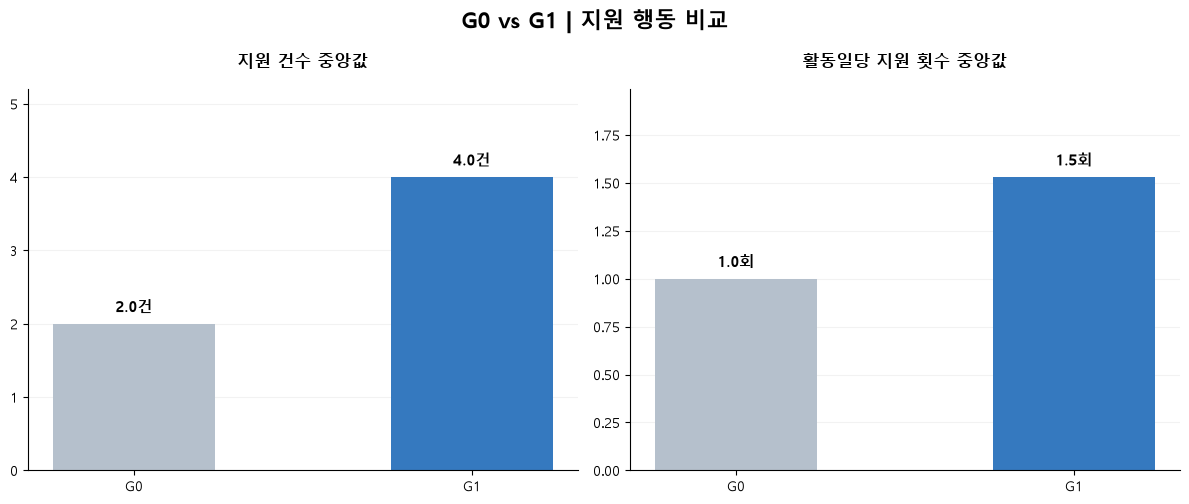

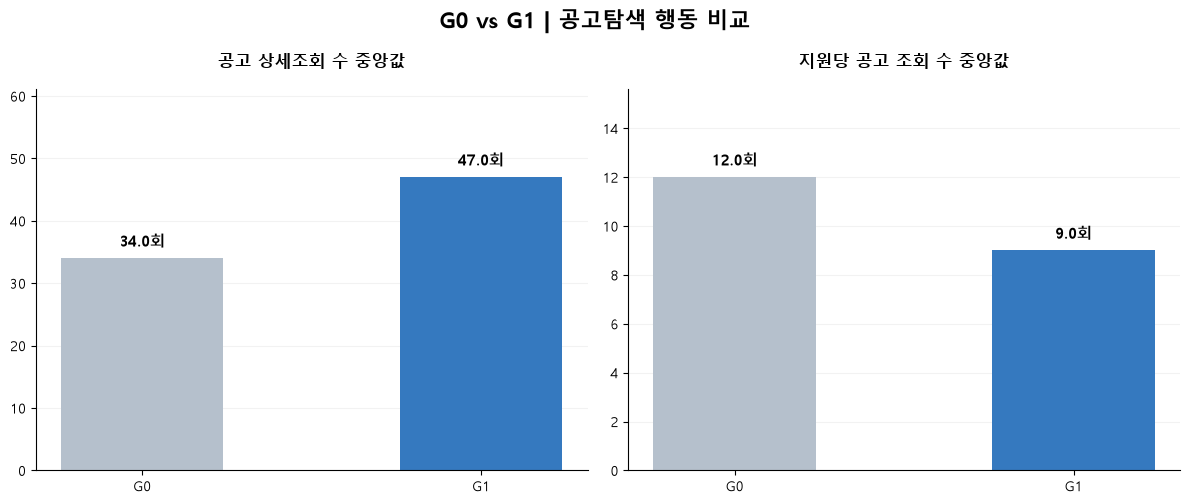

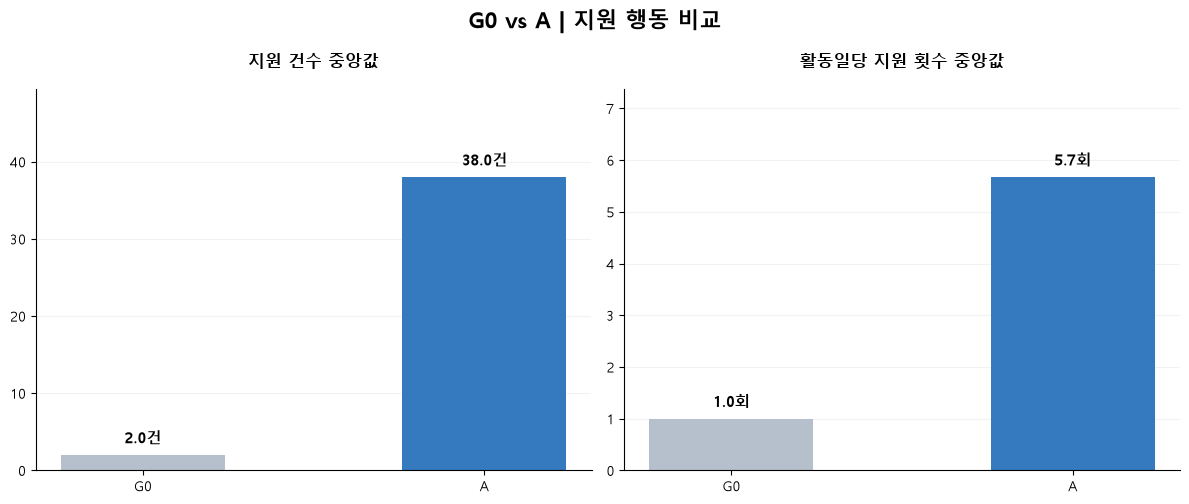

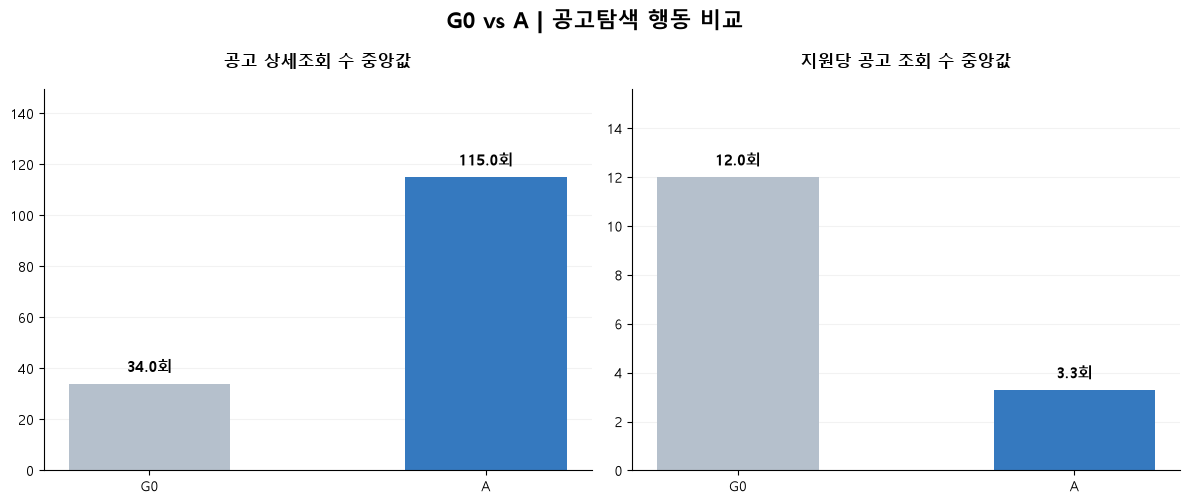

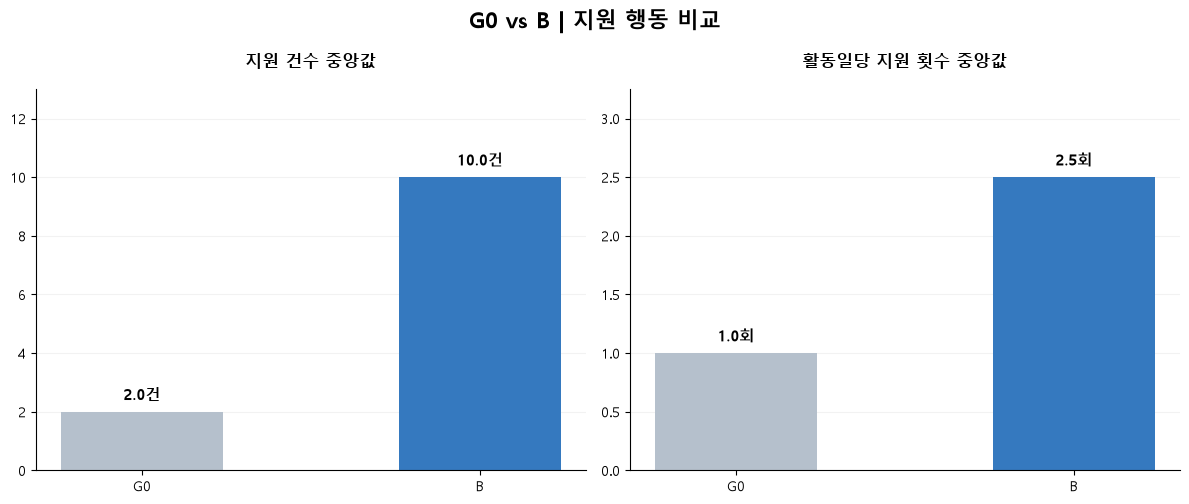

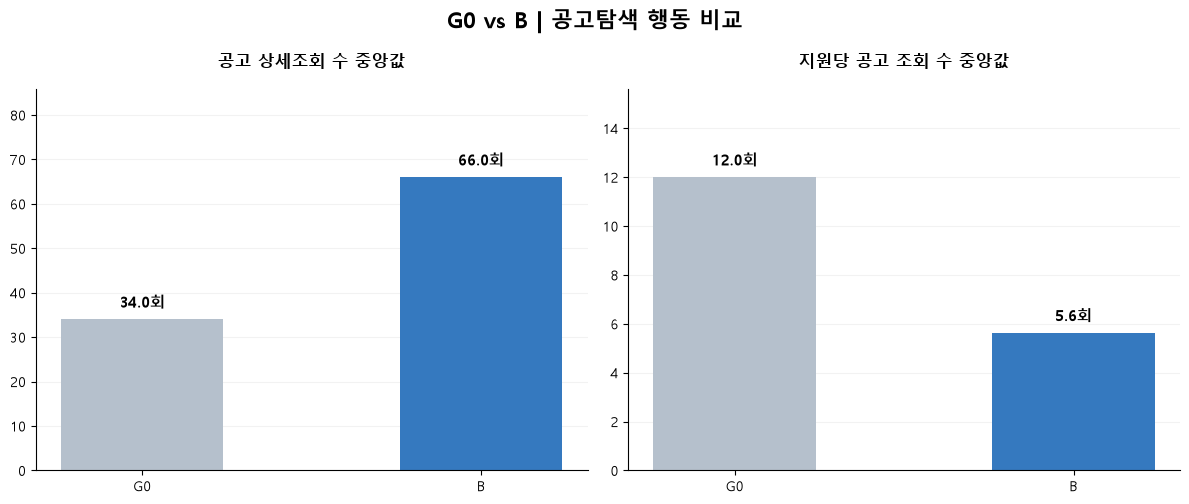

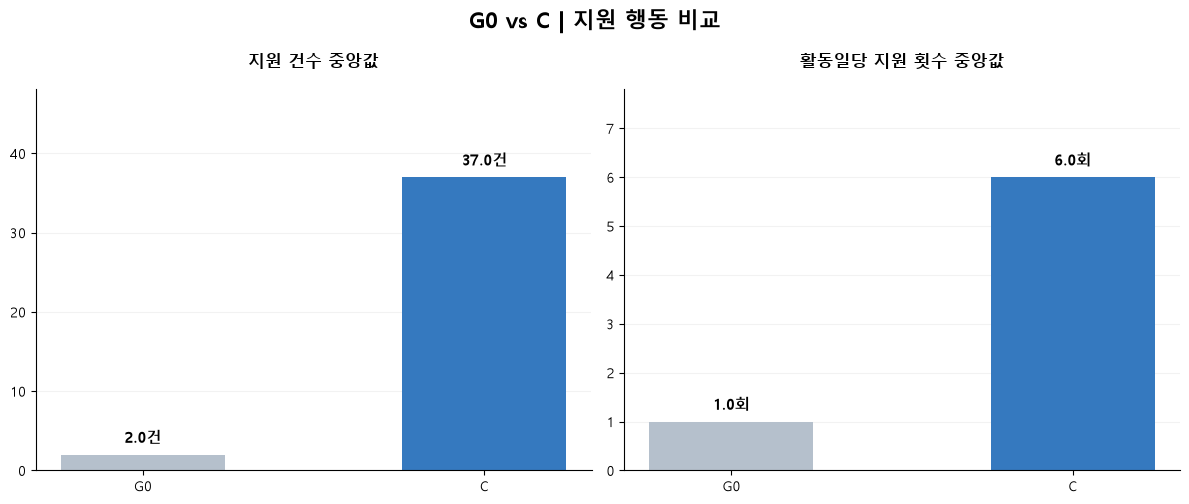

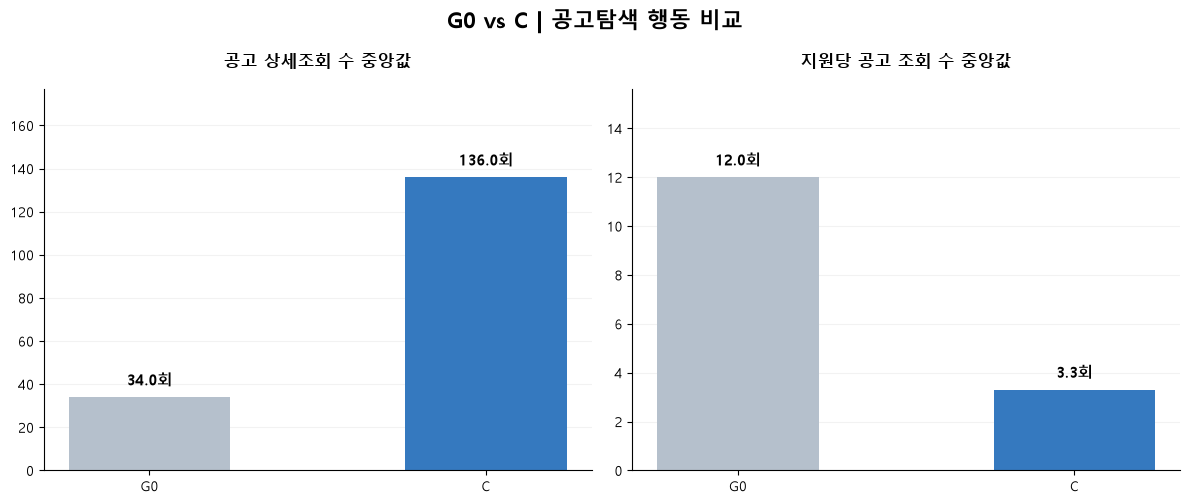

저장 완료: C:\Users\user\OneDrive\바탕 화면\codeit\프로젝트\중급 1 프로젝트\ppt_group_charts


In [170]:
from pathlib import Path
import matplotlib.pyplot as plt

save_dir = Path('ppt_group_charts')
save_dir.mkdir(exist_ok=True)

for target in ['G1', 'A', 'B', 'C']:
    for behavior in ['application', 'view']:
        summary = summarize_behavior(target, behavior)
        fig = plot_behavior(summary, target, behavior)

        fig.savefig(
            save_dir / f'G0_vs_{target}_{behavior}.png',
            dpi=200,
            bbox_inches='tight',
            facecolor='white'
        )
        plt.close(fig)

print(f'저장 완료: {save_dir.resolve()}')

# 14. 최종 사용자 세그먼트 정의 및 비즈니스 활용

**분석 목적:** 5개 행동 신호로 구분한 **G0·G1·A·B·C 다섯 주요 세그먼트**를 동일한 관점에서 설명하고, 관찰된 행동 차이를 구직자·기업 관점의 **검증 가능한 UX 개선 가설**로 연결한다.

- **모집단:** 2022~2023년 지원자 **10,287명**. G0 **6,484명**, G1 **2,941명**, 복합 신호군 **862명**.
- **복합 신호군:** A **151명**, B **492명**, C **171명**, **기타 48명**. 주요 다섯 세그먼트는 **10,239명**이며, 기타는 제외·삭제하지 않고 별도 관리한다.
- **해석 원칙:** 신호는 행동의 관찰값이며 **지원 의도·직무 적합성·채용 성과를 직접 증명하지 않는다.** 신호 0은 해당 행동 자체가 없다는 뜻이 아니다.

## 14-1. 세그먼트 정의 | 동일한 분석 프레임

| 그룹 | 유형명 | 분류 조건 | 관찰된 대표 특징 | 제품 개선 가설 |
|---|---|---|---|---|
| **G0** | 행동 신호 미탐지형 | 5개 신호 모두 0 | 지원 중앙값 **2건**, 조회 **34회** | 기본 탐색·지원 흐름의 접근성·편의성 개선 |
| **G1** | 단일 행동 신호형 | 신호 정확히 1개 | **71.4%**가 공고탐색성 신호; 지원 중앙값 **4건** | 빠른 지원 흐름을 유지하면서 필수 공고 정보 노출 |
| **A** | 다수 공고·적극 지원형 | 지원행동 신호 2개 이상 + 조회·북마크 신호 0 | 지원 **38건**, 지원당 조회 **3.29회** | 다수 지원 이력 관리, 유사 공고·자격요건 비교 |
| **B** | 탐색·지원 행동 결합형 | 지원행동 신호 정확히 1개 + 공고탐색성 1 + 북마크 신호 0 | 지원 **10건**, 지원당 조회 **5.63회** | 조회→지원 전환 시 핵심 조건 확인 지원 |
| **C** | 다수 공고·빠른 지원형 | 지원행동 신호 2개 이상 + 공고탐색성 1 + 북마크 신호 0 | 지원 **37건**, 지원당 조회 **3.31회** | 반복 지원 관리와 지원 직전 조건 확인 병행 |

**기타 복합형 48명:** 북마크탐색성 신호를 포함하는 집단으로, 주요 5개 유형 비교와 구분해 별도 관찰한다. 북마크 신호 0은 일반적인 북마크 사용 여부가 0이라는 뜻이 아니다.

**주의:** G1은 공고탐색성 사용자가 *다수*인 집단이지, 모든 G1 사용자가 빠른 조회→지원 신호를 보유한 것은 아니다. A와 C는 지원 규모·지원당 조회가 매우 비슷하며, **두 집단의 차이를 실질적 차이로 해석하지 않는다.**

## 14-2. 분석 코드 | 다섯 유형의 핵심 지표 요약

**집계 단위:** 사용자 1명당 1행. 지원당 조회·북마크 지표는 **사용자별 비율을 계산한 후 그룹 중앙값**을 집계한다. `활동일수`는 **지원이 발생한 날짜 수**이며 전체 플랫폼 로그인/접속일수와 다르다.

아래 코드는 13-5절에서 생성한 `all_group_summary`, `all_group_users`를 재사용하므로 중복 집계 로직을 만들지 않는다.

In [184]:
from IPython.display import display

# 13-5절의 사용자별 행동 지표 및 그룹별 요약 재사용
required_groups = ['G0', 'G1', 'A', 'B', 'C']
assert all_group_users['user_uuid'].is_unique, '사용자 중복이 있습니다.'
assert set(all_group_summary.index) == set(required_groups), '주요 다섯 그룹을 확인하세요.'
all_group_summary = all_group_summary.reindex(required_groups)
assert all_group_summary['사용자수'].notna().all(), '사용자 수 결측을 확인하세요.'
assert all_group_summary['사용자수'].sum() == 10239, '주요 다섯 유형 인원이 일치하지 않습니다.'

segment_name_map = {
    'G0': '행동 신호 미탐지형',
    'G1': '단일 행동 신호형',
    'A': '다수 공고·적극 지원형',
    'B': '즉시·지원 행동 결합형',
    'C': '다수 공고·빠른 지원형'
}

segment_profile = all_group_summary.copy()
segment_profile.insert(0, '유형명', segment_profile.index.map(segment_name_map))
segment_profile.insert(2, '전체대비(%)', (segment_profile['사용자수'] / 10287 * 100).round(1))

display(segment_profile)
print('주요 유형:', int(segment_profile['사용자수'].sum()), '명')
print('기타 복합형:', 10287 - int(segment_profile['사용자수'].sum()), '명')

,유형명,사용자수,전체대비(%),지원건수_중앙값,활동일수_중앙값,활동기간_중앙값,활동일당지원_중앙값,공고조회_중앙값,지원당조회_중앙값,지원당북마크_중앙값,북마크이용률
그룹,,,,,,,,,,,
G0,행동 신호 미탐지형,6484,63.0,2.0,1.0,1.08,1.00,34.0,12.00,0.18,53.12
G1,단일 행동 신호형,2941,28.6,4.0,3.0,17.81,1.53,47.0,9.00,0.17,56.41
A,다수 공고·적극 지원형,151,1.5,38.0,7.0,117.02,5.67,115.0,3.29,0.01,51.66
B,즉시·지원 행동 결합형,492,4.8,10.0,4.0,33.73,2.50,66.0,5.63,0.10,59.35
C,다수 공고·빠른 지원형,171,1.7,37.0,5.0,74.55,6.00,136.0,3.31,0.00,48.54


주요 유형: 10239 명
기타 복합형: 48 명


### 결과 해석 | 세그먼트별 지원·탐색의 상대적 규모

- **G0 → G1:** 지원 중앙값은 **2건 → 4건**, 공고 조회 중앙값은 **34회 → 47회**. G1은 단일 신호 집단이며, 그중 공고탐색성 신호가 가장 높은 비중을 차지한다.
- **A·C:** 지원 중앙값 **38건·37건**, 지원당 조회 중앙값 **3.29회·3.31회**로 유사하다. 따라서 **지원 규모만으로 A와 C가 구분된다고 설명하면 안 된다.**
- **B:** 지원 중앙값 **10건**, 지원당 조회 중앙값 **5.63회**. A·C보다 지원 규모는 작지만, 빠른 조회→지원 간격 신호가 결합된 유형이다.
- **지원당 조회:** G0 **12.00회**, G1 **9.00회**, A **3.29회**, B **5.63회**, C **3.31회**. 이는 지원 건수 대비 관찰된 상세조회 횟수이지, **지원한 공고 자체를 읽은 횟수**가 아니다.

**핵심:** 그룹별 절대 조회량과 지원당 조회량을 **함께** 해석해야 한다. 분류에 사용한 신호와 관련된 차이는 기술적 특징이며 독립적인 성과 검증이 아니다.

## 14-6. 최종 해석 | 관찰된 특성 → 서비스 개선 가설 → 후속 검증

| 그룹 | 관찰된 특성 | 구직자 UX 개선 가설 | 기업 측 개선 가설 | 검증 지표 예시 |
|---|---|---|---|---|
| **G0** | 다섯 신호 미탐지, 상대적으로 적은 지원량 | 공고 검색·필터·지원 기본 흐름의 사용성 개선 | 공고 정보 표준화 | 검색→상세조회 전환율, 지원 완료율 |
| **G1** | 단일 신호 중 공고탐색성 비중 71.4% | 빠른 지원 흐름을 유지하며 필수조건 요약 노출 | 필수 자격요건 명확화 | 핵심정보 확인율, 지원 완료율 |
| **A** | 다수 지원, 지원량 대비 조회·저장 비중 낮음 | 지원 이력 관리, 유사 공고 비교 | 공고 요건의 비교 가능성 강화 | 이력 관리 이용률, 지원 취소·중복 문의율 |
| **B** | 공고탐색성 + 지원행동 1개, 지원 중앙값 10건 | 상세조회→지원 사이 핵심 조건 확인 | 공고별 필수조건 가시성 개선 | 정보 확인율, 지원 완료율 |
| **C** | 복합 지원행동 + 공고탐색성, A와 지원량 유사 | 반복 지원 관리 + 지원 직전 조건 확인 | 지원자 검토 시 필요한 요건 정보 구조화 | 지원 이력 관리 이용률, 필수조건 확인율 |

**검증 계획:** 각 개선안을 기능 가설로 정의하고, 사용자 유형별 A/B 테스트에서 **지원 완료율·필수 정보 확인율·지원자 검토 효율** 등을 관찰한다. 기업의 실제 채용 성사율이나 지원자 적합성은 본 데이터로 확인할 수 없으므로 성과를 단정하지 않는다.

### 반드시 구분할 세 가지

1. **행동 신호는 채용 의도·지원 품질의 정답 라벨이 아니다.** G0도 정상·우수 지원자로 확정되지 않는다.
2. **공고 조회 로그와 실제 지원 공고의 동일성을 확인할 수 없다.** 공고탐색성은 동일 공고 열람이나 숙독의 증거가 아니다.
3. **A와 C의 지원 규모는 유사하다.** 차이는 공고탐색성 신호의 결합 구조이며, 추가 행동 검증 없이 별개의 성과 집단이라고 주장하지 않는다.

**최종 결론:** 본 분석은 채용 플랫폼의 양면 매칭 문제를 해결하기 위한 **행동 기반 세그먼테이션과 후속 UX 실험의 출발점**을 제공한다.